In [1]:
import os
import numpy as np
import pandas as pd

# =========================
# PCG paths
# =========================

PCG_ARRAY_PATH = "../processed/PCG/pcg_spectrograms.npy"
PCG_METADATA_PATH = "../processed/PCG/pcg_metadata.csv"

# =========================
# ECG paths
# =========================

ECG_ARRAY_PATH = "../processed/ECG/ecg_segments.npy"
ECG_METADATA_PATH = "../processed/ECG/ecg_metadata.csv"


# =========================
# Load PCG
# =========================

X_pcg = np.load(PCG_ARRAY_PATH)
pcg_metadata = pd.read_csv(PCG_METADATA_PATH)


# =========================
# Load ECG
# =========================

X_ecg = np.load(ECG_ARRAY_PATH)
ecg_metadata = pd.read_csv(ECG_METADATA_PATH)


# =========================
# Basic information
# =========================

print("PCG data shape:", X_pcg.shape)
print("PCG metadata shape:", pcg_metadata.shape)

print("\nECG data shape:", X_ecg.shape)
print("ECG metadata shape:", ecg_metadata.shape)

print("\nPCG unique recordings:",
      pcg_metadata["recording_id"].nunique())

print("ECG unique recordings:",
      ecg_metadata["recording_id"].nunique())

PCG data shape: (10866, 40, 19)
PCG metadata shape: (10866, 2)

ECG data shape: (6360, 4000)
ECG metadata shape: (6360, 7)

PCG unique recordings: 409
ECG unique recordings: 405


In [2]:
pcg_recordings = set(
    pcg_metadata["recording_id"].unique()
)

ecg_recordings = set(
    ecg_metadata["recording_id"].unique()
)

common_recordings = sorted(
    pcg_recordings.intersection(ecg_recordings)
)

pcg_only = sorted(
    pcg_recordings - ecg_recordings
)

ecg_only = sorted(
    ecg_recordings - pcg_recordings
)

print("PCG recordings       :", len(pcg_recordings))
print("ECG recordings       :", len(ecg_recordings))
print("Common recordings    :", len(common_recordings))
print("PCG-only recordings  :", len(pcg_only))
print("ECG-only recordings  :", len(ecg_only))

print("\nPCG-only IDs:")
print(pcg_only)

print("\nECG-only IDs:")
print(ecg_only[:10])

PCG recordings       : 409
ECG recordings       : 405
Common recordings    : 405
PCG-only recordings  : 4
ECG-only recordings  : 0

PCG-only IDs:
['a0041', 'a0117', 'a0220', 'a0233']

ECG-only IDs:
[]


In [3]:
# Get one label per recording from each modality

pcg_recording_labels = (
    pcg_metadata[["recording_id", "label"]]
    .drop_duplicates()
)

ecg_recording_labels = (
    ecg_metadata[["recording_id", "label"]]
    .drop_duplicates()
)

# Keep only recordings present in both modalities

pcg_common_labels = pcg_recording_labels[
    pcg_recording_labels["recording_id"].isin(common_recordings)
]

ecg_common_labels = ecg_recording_labels[
    ecg_recording_labels["recording_id"].isin(common_recordings)
]

# Compare labels

label_comparison = pcg_common_labels.merge(
    ecg_common_labels,
    on="recording_id",
    how="inner",
    suffixes=("_pcg", "_ecg")
)

mismatches = label_comparison[
    label_comparison["label_pcg"] != label_comparison["label_ecg"]
]

print("Common recordings checked:", len(label_comparison))
print("Label mismatches:", len(mismatches))

print("\nPCG label distribution:")
print(label_comparison["label_pcg"].value_counts())

print("\nECG label distribution:")
print(label_comparison["label_ecg"].value_counts())

if len(mismatches) > 0:
    print("\nMismatched recordings:")
    print(mismatches)

Common recordings checked: 405
Label mismatches: 0

PCG label distribution:
label_pcg
 1    288
-1    117
Name: count, dtype: int64

ECG label distribution:
label_ecg
 1    288
-1    117
Name: count, dtype: int64


In [4]:
import os

project_root = ".."

pcg_model_files = []

for root, dirs, files in os.walk(project_root):
    for file in files:
        if file.endswith(".keras") and "pcg" in file.lower():
            pcg_model_files.append(
                os.path.join(root, file)
            )

print("PCG model files found:")

if len(pcg_model_files) == 0:
    print("No PCG .keras model found.")
else:
    for path in pcg_model_files:
        print(path)

PCG model files found:
..\notebooks\best_pcg_cnn.keras
..\processed\PCG_ECG_best_attention_fusion.keras
..\processed\PCG_ECG_best_attention_fusion_clean.keras
..\processed\PCG\best_pcg_cnn_clean.keras


In [5]:
from tensorflow import keras

# Correct model paths
PCG_MODEL_PATH = "../notebooks/best_pcg_cnn.keras"
ECG_MODEL_PATH = "../processed/ECG/best_ecg_1dcnn.keras"

# Load trained models
pcg_model = keras.models.load_model(PCG_MODEL_PATH)
ecg_model = keras.models.load_model(ECG_MODEL_PATH)

print("PCG model loaded successfully!")
print("ECG model loaded successfully!")

print("\nPCG model input:", pcg_model.input_shape)
print("ECG model input:", ecg_model.input_shape)

PCG model loaded successfully!
ECG model loaded successfully!

PCG model input: (None, 40, 19, 1)
ECG model input: (None, 4000, 1)


In [6]:
from tensorflow import keras

# =========================
# PCG feature extractor
# =========================

pcg_input = keras.Input(shape=(40, 19, 1))

x = pcg_input

for layer in pcg_model.layers:
    if layer.name == pcg_model.layers[-1].name:
        break
    x = layer(x)

pcg_feature_extractor = keras.Model(
    inputs=pcg_input,
    outputs=x
)


# =========================
# ECG feature extractor
# =========================

ecg_input = keras.Input(shape=(4000, 1))

x = ecg_input

for layer in ecg_model.layers:
    if layer.name == ecg_model.layers[-1].name:
        break
    x = layer(x)

ecg_feature_extractor = keras.Model(
    inputs=ecg_input,
    outputs=x
)


# =========================
# Check output shapes
# =========================

print("PCG feature extractor created!")
print("ECG feature extractor created!")

print("\nPCG feature output shape:",
      pcg_feature_extractor.output_shape)

print("ECG feature output shape:",
      ecg_feature_extractor.output_shape)

PCG feature extractor created!
ECG feature extractor created!

PCG feature output shape: (None, 64)
ECG feature output shape: (None, 64)


In [7]:
# create common recording level dataset
# Create one common recording-level table
# using only recordings that have both PCG and ECG

common_recordings_df = (
    pcg_metadata[pcg_metadata["recording_id"].isin(common_recordings)]
    [["recording_id", "label"]]
    .drop_duplicates()
    .sort_values("recording_id")
    .reset_index(drop=True)
)

print("Common recordings:", len(common_recordings_df))

print("\nLabel distribution:")
print(common_recordings_df["label"].value_counts())

print("\nFirst 10 recordings:")
print(common_recordings_df.head(10))

print("\nLast 10 recordings:")
print(common_recordings_df.tail(10))

Common recordings: 405

Label distribution:
label
 1    288
-1    117
Name: count, dtype: int64

First 10 recordings:
  recording_id  label
0        a0001      1
1        a0002      1
2        a0003      1
3        a0004      1
4        a0005      1
5        a0006      1
6        a0007     -1
7        a0008      1
8        a0009     -1
9        a0010      1

Last 10 recordings:
    recording_id  label
395        a0400      1
396        a0401     -1
397        a0402      1
398        a0403      1
399        a0404      1
400        a0405     -1
401        a0406     -1
402        a0407     -1
403        a0408     -1
404        a0409     -1


In [8]:
from sklearn.model_selection import train_test_split

# First split: 70% train, 30% temporary
train_records, temp_records = train_test_split(
    common_recordings_df,
    test_size=0.30,
    stratify=common_recordings_df["label"],
    random_state=42
)

# Second split: 15% validation, 15% test
val_records, test_records = train_test_split(
    temp_records,
    test_size=0.50,
    stratify=temp_records["label"],
    random_state=42
)

# Reset indexes
train_records = train_records.reset_index(drop=True)
val_records = val_records.reset_index(drop=True)
test_records = test_records.reset_index(drop=True)

print("Train recordings:", len(train_records))
print("Validation recordings:", len(val_records))
print("Test recordings:", len(test_records))

print("\nTrain label distribution:")
print(train_records["label"].value_counts())

print("\nValidation label distribution:")
print(val_records["label"].value_counts())

print("\nTest label distribution:")
print(test_records["label"].value_counts())

Train recordings: 283
Validation recordings: 61
Test recordings: 61

Train label distribution:
label
 1    201
-1     82
Name: count, dtype: int64

Validation label distribution:
label
 1    44
-1    17
Name: count, dtype: int64

Test label distribution:
label
 1    43
-1    18
Name: count, dtype: int64


In [9]:
# Create sets of recording IDs for each split

train_ids = set(train_records["recording_id"])
val_ids = set(val_records["recording_id"])
test_ids = set(test_records["recording_id"])


# =========================
# PCG segment assignment
# =========================

pcg_train_mask = pcg_metadata["recording_id"].isin(train_ids)
pcg_val_mask = pcg_metadata["recording_id"].isin(val_ids)
pcg_test_mask = pcg_metadata["recording_id"].isin(test_ids)

X_pcg_train = X_pcg[pcg_train_mask]
X_pcg_val = X_pcg[pcg_val_mask]
X_pcg_test = X_pcg[pcg_test_mask]


# =========================
# ECG segment assignment
# =========================

ecg_train_mask = ecg_metadata["recording_id"].isin(train_ids)
ecg_val_mask = ecg_metadata["recording_id"].isin(val_ids)
ecg_test_mask = ecg_metadata["recording_id"].isin(test_ids)

X_ecg_train = X_ecg[ecg_train_mask]
X_ecg_val = X_ecg[ecg_val_mask]
X_ecg_test = X_ecg[ecg_test_mask]


# =========================
# Print results
# =========================

print("PCG:")
print("Train:", X_pcg_train.shape)
print("Validation:", X_pcg_val.shape)
print("Test:", X_pcg_test.shape)

print("\nECG:")
print("Train:", X_ecg_train.shape)
print("Validation:", X_ecg_val.shape)
print("Test:", X_ecg_test.shape)

PCG:
Train: (7479, 40, 19)
Validation: (1650, 40, 19)
Test: (1621, 40, 19)

ECG:
Train: (4425, 4000)
Validation: (975, 4000)
Test: (960, 4000)


In [10]:
# Add channel dimension required by the CNNs
X_pcg_train_cnn = X_pcg_train[..., np.newaxis]
X_pcg_val_cnn = X_pcg_val[..., np.newaxis]
X_pcg_test_cnn = X_pcg_test[..., np.newaxis]

X_ecg_train_cnn = X_ecg_train[..., np.newaxis]
X_ecg_val_cnn = X_ecg_val[..., np.newaxis]
X_ecg_test_cnn = X_ecg_test[..., np.newaxis]


# =========================
# Extract PCG features
# =========================

pcg_features_train = pcg_feature_extractor.predict(
    X_pcg_train_cnn,
    verbose=0
)

pcg_features_val = pcg_feature_extractor.predict(
    X_pcg_val_cnn,
    verbose=0
)

pcg_features_test = pcg_feature_extractor.predict(
    X_pcg_test_cnn,
    verbose=0
)


# =========================
# Extract ECG features
# =========================

ecg_features_train = ecg_feature_extractor.predict(
    X_ecg_train_cnn,
    verbose=0
)

ecg_features_val = ecg_feature_extractor.predict(
    X_ecg_val_cnn,
    verbose=0
)

ecg_features_test = ecg_feature_extractor.predict(
    X_ecg_test_cnn,
    verbose=0
)


# =========================
# Check shapes
# =========================

print("PCG features:")
print("Train:", pcg_features_train.shape)
print("Validation:", pcg_features_val.shape)
print("Test:", pcg_features_test.shape)

print("\nECG features:")
print("Train:", ecg_features_train.shape)
print("Validation:", ecg_features_val.shape)
print("Test:", ecg_features_test.shape)

PCG features:
Train: (7479, 64)
Validation: (1650, 64)
Test: (1621, 64)

ECG features:
Train: (4425, 64)
Validation: (975, 64)
Test: (960, 64)


In [11]:
def aggregate_features_by_recording(features, metadata):
    """
    Convert segment-level features into one
    recording-level feature vector using mean aggregation.
    """

    feature_df = pd.DataFrame(features)
    feature_df["recording_id"] = metadata["recording_id"].values

    recording_features = (
        feature_df
        .groupby("recording_id")
        .mean(numeric_only=True)
        .reset_index()
    )

    return recording_features


# =========================
# PCG recording-level features
# =========================

pcg_train_recording_features = aggregate_features_by_recording(
    pcg_features_train,
    pcg_metadata.loc[pcg_train_mask].reset_index(drop=True)
)

pcg_val_recording_features = aggregate_features_by_recording(
    pcg_features_val,
    pcg_metadata.loc[pcg_val_mask].reset_index(drop=True)
)

pcg_test_recording_features = aggregate_features_by_recording(
    pcg_features_test,
    pcg_metadata.loc[pcg_test_mask].reset_index(drop=True)
)


# =========================
# ECG recording-level features
# =========================

ecg_train_recording_features = aggregate_features_by_recording(
    ecg_features_train,
    ecg_metadata.loc[ecg_train_mask].reset_index(drop=True)
)

ecg_val_recording_features = aggregate_features_by_recording(
    ecg_features_val,
    ecg_metadata.loc[ecg_val_mask].reset_index(drop=True)
)

ecg_test_recording_features = aggregate_features_by_recording(
    ecg_features_test,
    ecg_metadata.loc[ecg_test_mask].reset_index(drop=True)
)


# =========================
# Check results
# =========================

print("PCG recording-level:")
print("Train:", pcg_train_recording_features.shape)
print("Validation:", pcg_val_recording_features.shape)
print("Test:", pcg_test_recording_features.shape)

print("\nECG recording-level:")
print("Train:", ecg_train_recording_features.shape)
print("Validation:", ecg_val_recording_features.shape)
print("Test:", ecg_test_recording_features.shape)

PCG recording-level:
Train: (283, 65)
Validation: (61, 65)
Test: (61, 65)

ECG recording-level:
Train: (283, 65)
Validation: (61, 65)
Test: (61, 65)


In [12]:
# =========================
# Combine PCG and ECG features
# =========================

def combine_modalities(pcg_features, ecg_features, records_df):

    # Rename feature columns
    pcg_features = pcg_features.rename(
        columns={
            col: f"pcg_{col}"
            for col in pcg_features.columns
            if col != "recording_id"
        }
    )

    ecg_features = ecg_features.rename(
        columns={
            col: f"ecg_{col}"
            for col in ecg_features.columns
            if col != "recording_id"
        }
    )

    # Merge using recording ID
    combined = pcg_features.merge(
        ecg_features,
        on="recording_id",
        how="inner"
    )

    # Add true label
    combined = combined.merge(
        records_df[["recording_id", "label"]],
        on="recording_id",
        how="inner"
    )

    return combined


# Train
multimodal_train = combine_modalities(
    pcg_train_recording_features,
    ecg_train_recording_features,
    train_records
)

# Validation
multimodal_val = combine_modalities(
    pcg_val_recording_features,
    ecg_val_recording_features,
    val_records
)

# Test
multimodal_test = combine_modalities(
    pcg_test_recording_features,
    ecg_test_recording_features,
    test_records
)


# =========================
# Check results
# =========================

print("Multimodal train shape:", multimodal_train.shape)
print("Multimodal validation shape:", multimodal_val.shape)
print("Multimodal test shape:", multimodal_test.shape)

print("\nTrain labels:")
print(multimodal_train["label"].value_counts())

print("\nValidation labels:")
print(multimodal_val["label"].value_counts())

print("\nTest labels:")
print(multimodal_test["label"].value_counts())

print("\nMissing values:")
print("Train:", multimodal_train.isna().sum().sum())
print("Validation:", multimodal_val.isna().sum().sum())
print("Test:", multimodal_test.isna().sum().sum())

Multimodal train shape: (283, 130)
Multimodal validation shape: (61, 130)
Multimodal test shape: (61, 130)

Train labels:
label
 1    201
-1     82
Name: count, dtype: int64

Validation labels:
label
 1    44
-1    17
Name: count, dtype: int64

Test labels:
label
 1    43
-1    18
Name: count, dtype: int64

Missing values:
Train: 0
Validation: 0
Test: 0


In [13]:
# =========================
# Separate PCG and ECG features
# =========================

pcg_feature_cols = [
    col for col in multimodal_train.columns
    if col.startswith("pcg_")
]

ecg_feature_cols = [
    col for col in multimodal_train.columns
    if col.startswith("ecg_")
]


# Training data
X_pcg_fusion_train = multimodal_train[pcg_feature_cols].values
X_ecg_fusion_train = multimodal_train[ecg_feature_cols].values
y_fusion_train = (multimodal_train["label"] == 1).astype(np.int32).values


# Validation data
X_pcg_fusion_val = multimodal_val[pcg_feature_cols].values
X_ecg_fusion_val = multimodal_val[ecg_feature_cols].values
y_fusion_val = (multimodal_val["label"] == 1).astype(np.int32).values


# Test data
X_pcg_fusion_test = multimodal_test[pcg_feature_cols].values
X_ecg_fusion_test = multimodal_test[ecg_feature_cols].values
y_fusion_test = (multimodal_test["label"] == 1).astype(np.int32).values


# =========================
# Check shapes
# =========================

print("PCG fusion features:")
print("Train:", X_pcg_fusion_train.shape)
print("Validation:", X_pcg_fusion_val.shape)
print("Test:", X_pcg_fusion_test.shape)

print("\nECG fusion features:")
print("Train:", X_ecg_fusion_train.shape)
print("Validation:", X_ecg_fusion_val.shape)
print("Test:", X_ecg_fusion_test.shape)

print("\nLabels:")
print("Train:", y_fusion_train.shape)
print("Validation:", y_fusion_val.shape)
print("Test:", y_fusion_test.shape)

print("\nUnique labels:", np.unique(y_fusion_train))

PCG fusion features:
Train: (283, 64)
Validation: (61, 64)
Test: (61, 64)

ECG fusion features:
Train: (283, 64)
Validation: (61, 64)
Test: (61, 64)

Labels:
Train: (283,)
Validation: (61,)
Test: (61,)

Unique labels: [0 1]


In [14]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# =========================
# Inputs
# =========================

pcg_input = keras.Input(
    shape=(64,),
    name="pcg_features"
)

ecg_input = keras.Input(
    shape=(64,),
    name="ecg_features"
)


# =========================
# Project each modality
# =========================

pcg_projection = layers.Dense(
    64,
    activation="relu",
    name="pcg_projection"
)(pcg_input)

ecg_projection = layers.Dense(
    64,
    activation="relu",
    name="ecg_projection"
)(ecg_input)


# =========================
# Add modality dimension
# =========================

pcg_token = layers.Reshape((1, 64))(
    pcg_projection
)

ecg_token = layers.Reshape((1, 64))(
    ecg_projection
)


# =========================
# Stack PCG + ECG
# Shape: (batch, 2, 64)
# =========================

modalities = layers.Concatenate(axis=1)(
    [pcg_token, ecg_token]
)


# =========================
# Attention across modalities
# =========================

attention_output = layers.MultiHeadAttention(
    num_heads=2,
    key_dim=32,
    name="multimodal_attention"
)(
    modalities,
    modalities
)


# =========================
# Residual connection
# =========================

attention_output = layers.Add()(
    [modalities, attention_output]
)

attention_output = layers.LayerNormalization()(
    attention_output
)


# =========================
# Flatten fused representation
# =========================

fusion_features = layers.Flatten(
    name="fused_features"
)(attention_output)


# =========================
# Classification head
# =========================

x = layers.Dense(
    64,
    activation="relu"
)(fusion_features)

x = layers.Dropout(0.3)(x)

x = layers.Dense(
    32,
    activation="relu"
)(x)

x = layers.Dropout(0.2)(x)

output = layers.Dense(
    1,
    activation="sigmoid",
    name="rhd_probability"
)(x)


# =========================
# Create model
# =========================

fusion_model = keras.Model(
    inputs=[pcg_input, ecg_input],
    outputs=output,
    name="PCG_ECG_Attention_Fusion"
)


# =========================
# Compile
# =========================

fusion_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)


# =========================
# Model summary
# =========================

fusion_model.summary()

Model: "PCG_ECG_Attention_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ pcg_features (InputLayer)     │ (None, 64)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ ecg_features (InputLayer)     │ (None, 64)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pcg_projection (Dense)        │ (None, 64)                │           4,160 │ pcg_features[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ ecg_projection (Dense)        │ (None, 64)                │           4,160 │ ecg_features[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape (Reshape)             │ (None, 1, 64)             │               0 │ pcg_projection[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape_1 (Reshape)           │ (None, 1, 64)             │               0 │ ecg_projection[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 2, 64)             │               0 │ reshape[0][0],             │
│                               │                           │                 │ reshape_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multimodal_attention          │ (None, 2, 64)             │          16,640 │ concatenate[0][0],         │
│ (MultiHeadAttention)          │                           │                 │ concatenate[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 2, 64)             │               0 │ concatenate[0][0],         │
│                               │                           │                 │ multimodal_attention[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization           │ (None, 2, 64)             │             128 │ add[0][0]                  │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fused_features (Flatten)      │ (None, 128)               │               0 │ layer_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 64)                │           8,256 │ fused_features[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 64)                │               0 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 32)                │           2,080 │ dropout_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_2 (Dropout)           │ (None, 32)                │               0 │ dense_1[0][0]              │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 35,457 (138.50 KB)

 Trainable params: 35,457 (138.50 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_fusion_train)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_fusion_train
)

fusion_class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, class_weights_array)
}

print("Classes:", classes)
print("Class weights:", fusion_class_weights)

Classes: [0 1]
Class weights: {0: 1.725609756097561, 1: 0.7039800995024875}


In [16]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# =========================
# Callbacks
# =========================

early_stopping = EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "../processed/PCG_ECG_best_attention_fusion.keras",
    monitor="val_auc",
    mode="max",
    save_best_only=True,
    verbose=1
)


# =========================
# Train
# =========================

history = fusion_model.fit(
    {
        "pcg_features": X_pcg_fusion_train,
        "ecg_features": X_ecg_fusion_train
    },
    y_fusion_train,

    validation_data=(
        {
            "pcg_features": X_pcg_fusion_val,
            "ecg_features": X_ecg_fusion_val
        },
        y_fusion_val
    ),

    epochs=50,
    batch_size=16,

    class_weight=fusion_class_weights,

    callbacks=[
        early_stopping,
        checkpoint
    ],

    verbose=1
)

Epoch 1/50
13/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7452 - auc: 0.7493 - loss: 0.5887 - precision: 0.8676 - recall: 0.7712
Epoch 1: val_auc improved from None to 0.94251, saving model to ../processed/PCG_ECG_best_attention_fusion.keras

Epoch 1: finished saving model to ../processed/PCG_ECG_best_attention_fusion.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.7703 - auc: 0.7988 - loss: 0.5443 - precision: 0.8696 - recall: 0.7960 - val_accuracy: 0.8361 - val_auc: 0.9425 - val_loss: 0.4253 - val_precision: 0.9722 - val_recall: 0.7955
Epoch 2/50
 1/18 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6875 - auc: 0.7578 - loss: 0.6974 - precision: 0.7143 - recall: 0.6250
Epoch 2: val_auc did not improve from 0.94251
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8233 - auc: 0.9117 - loss: 0.3730 - precision: 0.9314 - recall: 0.8109 - val_accuracy: 0.9180 - val_auc: 0.9278 - val_loss: 0.3013 - val_precision: 0.9333 - val_recall: 0.9545
Epoch 3/50
17/18 ━━━━━━━━━━

In [17]:
# =========================
# Generate probabilities
# =========================

val_probabilities = fusion_model.predict(
    {
        "pcg_features": X_pcg_fusion_val,
        "ecg_features": X_ecg_fusion_val
    },
    verbose=0
).ravel()

test_probabilities = fusion_model.predict(
    {
        "pcg_features": X_pcg_fusion_test,
        "ecg_features": X_ecg_fusion_test
    },
    verbose=0
).ravel()


# =========================
# Check results
# =========================

print("Validation probabilities:")
print("Shape:", val_probabilities.shape)
print("Min:", val_probabilities.min())
print("Max:", val_probabilities.max())
print("Mean:", val_probabilities.mean())

print("\nTest probabilities:")
print("Shape:", test_probabilities.shape)
print("Min:", test_probabilities.min())
print("Max:", test_probabilities.max())
print("Mean:", test_probabilities.mean())

Validation probabilities:
Shape: (61,)
Min: 0.040219802
Max: 0.9364889
Mean: 0.52815306

Test probabilities:
Shape: (61,)
Min: 0.04594379
Max: 0.929085
Mean: 0.52558845


In [18]:
from sklearn.metrics import roc_auc_score, roc_curve

# =========================
# Validation ROC-AUC
# =========================

val_auc = roc_auc_score(
    y_fusion_val,
    val_probabilities
)

print("Validation ROC-AUC:", val_auc)


# =========================
# ROC curve
# =========================

fpr, tpr, thresholds = roc_curve(
    y_fusion_val,
    val_probabilities
)


# =========================
# Youden's Index
# J = Sensitivity + Specificity - 1
# =========================

specificity = 1 - fpr

youden_index = tpr + specificity - 1

best_idx = np.argmax(youden_index)

best_threshold = thresholds[best_idx]

best_sensitivity = tpr[best_idx]
best_specificity = specificity[best_idx]
best_youden = youden_index[best_idx]


# =========================
# Results
# =========================

print("\nBest validation threshold:", best_threshold)
print("Validation sensitivity:", best_sensitivity)
print("Validation specificity:", best_specificity)
print("Youden's Index:", best_youden)

Validation ROC-AUC: 0.9425133689839572

Best validation threshold: 0.4127747714519501
Validation sensitivity: 0.8636363636363636
Validation specificity: 0.9411764705882353
Youden's Index: 0.8048128342245988


In [19]:
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# =========================
# Apply validation threshold
# =========================

test_predictions = (
    test_probabilities >= best_threshold
).astype(np.int32)


# =========================
# Test ROC-AUC
# =========================

test_auc = roc_auc_score(
    y_fusion_test,
    test_probabilities
)


# =========================
# Classification metrics
# =========================

test_accuracy = accuracy_score(
    y_fusion_test,
    test_predictions
)

test_precision = precision_score(
    y_fusion_test,
    test_predictions,
    zero_division=0
)

test_sensitivity = recall_score(
    y_fusion_test,
    test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    y_fusion_test,
    test_predictions,
    zero_division=0
)


# =========================
# Confusion matrix
# =========================

cm = confusion_matrix(
    y_fusion_test,
    test_predictions
)

tn, fp, fn, tp = cm.ravel()

test_specificity = tn / (tn + fp)


# =========================
# Print final results
# =========================

print("===== MULTIMODAL TEST RESULTS =====")

print("Test ROC-AUC:", test_auc)
print("Accuracy:", test_accuracy)
print("Precision:", test_precision)
print("Sensitivity:", test_sensitivity)
print("Specificity:", test_specificity)
print("F1 Score:", test_f1)

print("\nConfusion Matrix:")
print(cm)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

===== MULTIMODAL TEST RESULTS =====
Test ROC-AUC: 0.8087855297157623
Accuracy: 0.7213114754098361
Precision: 0.8421052631578947
Sensitivity: 0.7441860465116279
Specificity: 0.6666666666666666
F1 Score: 0.7901234567901234

Confusion Matrix:
[[12  6]
 [11 32]]

TN: 12
FP: 6
FN: 11
TP: 32


In [20]:
# Cell 19: Prepare leakage-controlled PCG and ECG branch data

# -----------------------------
# PCG data
# -----------------------------
pcg_train_mask = pcg_metadata["recording_id"].isin(train_ids)
pcg_val_mask   = pcg_metadata["recording_id"].isin(val_ids)
pcg_test_mask  = pcg_metadata["recording_id"].isin(test_ids)

X_pcg_clean_train = X_pcg[pcg_train_mask]
X_pcg_clean_val   = X_pcg[pcg_val_mask]
X_pcg_clean_test  = X_pcg[pcg_test_mask]

y_pcg_clean_train = (
    pcg_metadata.loc[pcg_train_mask, "label"].values == 1
).astype(np.int32)

y_pcg_clean_val = (
    pcg_metadata.loc[pcg_val_mask, "label"].values == 1
).astype(np.int32)

y_pcg_clean_test = (
    pcg_metadata.loc[pcg_test_mask, "label"].values == 1
).astype(np.int32)


# -----------------------------
# ECG data
# -----------------------------
ecg_train_mask = ecg_metadata["recording_id"].isin(train_ids)
ecg_val_mask   = ecg_metadata["recording_id"].isin(val_ids)
ecg_test_mask  = ecg_metadata["recording_id"].isin(test_ids)

X_ecg_clean_train = X_ecg[ecg_train_mask]
X_ecg_clean_val   = X_ecg[ecg_val_mask]
X_ecg_clean_test  = X_ecg[ecg_test_mask]

y_ecg_clean_train = (
    ecg_metadata.loc[ecg_train_mask, "label"].values == 1
).astype(np.int32)

y_ecg_clean_val = (
    ecg_metadata.loc[ecg_val_mask, "label"].values == 1
).astype(np.int32)

y_ecg_clean_test = (
    ecg_metadata.loc[ecg_test_mask, "label"].values == 1
).astype(np.int32)


# -----------------------------
# Add CNN channel dimension
# -----------------------------
X_pcg_clean_train_cnn = X_pcg_clean_train[..., np.newaxis]
X_pcg_clean_val_cnn   = X_pcg_clean_val[..., np.newaxis]
X_pcg_clean_test_cnn  = X_pcg_clean_test[..., np.newaxis]

X_ecg_clean_train_cnn = X_ecg_clean_train[..., np.newaxis]
X_ecg_clean_val_cnn   = X_ecg_clean_val[..., np.newaxis]
X_ecg_clean_test_cnn  = X_ecg_clean_test[..., np.newaxis]


# -----------------------------
# Display verification
# -----------------------------
print("PCG:")
print("Train:", X_pcg_clean_train_cnn.shape)
print("Val  :", X_pcg_clean_val_cnn.shape)
print("Test :", X_pcg_clean_test_cnn.shape)

print("\nECG:")
print("Train:", X_ecg_clean_train_cnn.shape)
print("Val  :", X_ecg_clean_val_cnn.shape)
print("Test :", X_ecg_clean_test_cnn.shape)

print("\nPCG train labels:", np.bincount(y_pcg_clean_train))
print("PCG val labels  :", np.bincount(y_pcg_clean_val))
print("PCG test labels :", np.bincount(y_pcg_clean_test))

print("\nECG train labels:", np.bincount(y_ecg_clean_train))
print("ECG val labels  :", np.bincount(y_ecg_clean_val))
print("ECG test labels :", np.bincount(y_ecg_clean_test))

PCG:
Train: (7479, 40, 19, 1)
Val  : (1650, 40, 19, 1)
Test : (1621, 40, 19, 1)

ECG:
Train: (4425, 4000, 1)
Val  : (975, 4000, 1)
Test : (960, 4000, 1)

PCG train labels: [2171 5308]
PCG val labels  : [ 470 1180]
PCG test labels : [ 458 1163]

ECG train labels: [1291 3134]
ECG val labels  : [280 695]
ECG test labels : [272 688]


In [21]:
# Cell 20: Build a fresh PCG CNN for the leakage-controlled experiment

from tensorflow import keras
from tensorflow.keras import layers

clean_pcg_model = keras.Sequential([
    layers.Input(shape=(40, 19, 1)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid", name="rhd_probability")
])

clean_pcg_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

clean_pcg_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 40, 19, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 40, 19, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 20, 9, 32)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 20, 9, 64)           │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 20, 9, 64)           │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 10, 4, 64)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 10, 4, 128)          │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 10, 4, 128)          │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rhd_probability (Dense)              │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,889 (398.00 KB)

 Trainable params: 101,441 (396.25 KB)

 Non-trainable params: 448 (1.75 KB)

In [22]:
# Cell 21: Calculate class weights for clean PCG training

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

pcg_classes = np.unique(y_pcg_clean_train)

pcg_class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=pcg_classes,
    y=y_pcg_clean_train
)

clean_pcg_class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(pcg_classes, pcg_class_weights_array)
}

print("PCG class weights:")
print(clean_pcg_class_weights)

PCG class weights:
{0: 1.7224781206817135, 1: 0.7045026375282593}


In [23]:
# Cell 22: Train the leakage-controlled PCG CNN

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

pcg_early_stopping = EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

pcg_checkpoint = ModelCheckpoint(
    "../processed/PCG/best_pcg_cnn_clean.keras",
    monitor="val_auc",
    mode="max",
    save_best_only=True,
    verbose=1
)

pcg_history = clean_pcg_model.fit(
    X_pcg_clean_train_cnn,
    y_pcg_clean_train,
    validation_data=(
        X_pcg_clean_val_cnn,
        y_pcg_clean_val
    ),
    epochs=50,
    batch_size=32,
    class_weight=clean_pcg_class_weights,
    callbacks=[
        pcg_early_stopping,
        pcg_checkpoint
    ],
    verbose=1
)

print("\nTraining completed.")
print("Epochs trained:", len(pcg_history.history["loss"]))
print(
    "Best validation AUC:",
    max(pcg_history.history["val_auc"])
)

Epoch 1/50
232/234 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7127 - auc: 0.7894 - loss: 0.5578 - precision: 0.8668 - recall: 0.7031
Epoch 1: val_auc improved from None to 0.79668, saving model to ../processed/PCG/best_pcg_cnn_clean.keras

Epoch 1: finished saving model to ../processed/PCG/best_pcg_cnn_clean.keras
234/234 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.7131 - auc: 0.7901 - loss: 0.5569 - precision: 0.8673 - recall: 0.7033 - val_accuracy: 0.7139 - val_auc: 0.7967 - val_loss: 0.5341 - val_precision: 0.7275 - val_recall: 0.9593
Epoch 2/50
234/234 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7492 - auc: 0.8419 - loss: 0.4910 - precision: 0.9009 - recall: 0.7265
Epoch 2: val_auc did not improve from 0.79668
234/234 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.7492 - auc: 0.8419 - loss: 0.4910 - precision: 0.9009 - recall: 0.7265 - val_accuracy: 0.7497 - val_auc: 0.7920 - val_loss: 0.5357 - val_precision: 0.8367 - val_recall: 0.8076
Epoch 3/50
234/234 ━━━━━━━━━━━━

In [24]:
# Cell 23: Recording-level evaluation of the clean PCG CNN

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve
)

# -----------------------------------
# Predict segment-level probabilities
# -----------------------------------
pcg_clean_val_prob = clean_pcg_model.predict(
    X_pcg_clean_val_cnn,
    verbose=0
).ravel()

pcg_clean_test_prob = clean_pcg_model.predict(
    X_pcg_clean_test_cnn,
    verbose=0
).ravel()


# -----------------------------------
# Create metadata copies
# -----------------------------------
pcg_val_metadata_clean = pcg_metadata.loc[
    pcg_val_mask,
    ["recording_id", "label"]
].reset_index(drop=True)

pcg_test_metadata_clean = pcg_metadata.loc[
    pcg_test_mask,
    ["recording_id", "label"]
].reset_index(drop=True)


# -----------------------------------
# Attach probabilities
# -----------------------------------
pcg_val_prediction_df = pcg_val_metadata_clean.copy()
pcg_val_prediction_df["probability"] = pcg_clean_val_prob

pcg_test_prediction_df = pcg_test_metadata_clean.copy()
pcg_test_prediction_df["probability"] = pcg_clean_test_prob


# -----------------------------------
# Aggregate segments → recording
# -----------------------------------
pcg_val_recording_df = (
    pcg_val_prediction_df
    .groupby("recording_id")
    .agg(
        true_label=("label", "first"),
        predicted_probability=("probability", "mean"),
        num_segments=("probability", "count")
    )
    .reset_index()
)

pcg_test_recording_df = (
    pcg_test_prediction_df
    .groupby("recording_id")
    .agg(
        true_label=("label", "first"),
        predicted_probability=("probability", "mean"),
        num_segments=("probability", "count")
    )
    .reset_index()
)


# -----------------------------------
# Binary labels
# -----------------------------------
y_val_recording = (
    pcg_val_recording_df["true_label"] == 1
).astype(np.int32)

y_test_recording = (
    pcg_test_recording_df["true_label"] == 1
).astype(np.int32)

val_recording_prob = pcg_val_recording_df[
    "predicted_probability"
].values

test_recording_prob = pcg_test_recording_df[
    "predicted_probability"
].values


# -----------------------------------
# Validation ROC-AUC
# -----------------------------------
val_recording_auc = roc_auc_score(
    y_val_recording,
    val_recording_prob
)

print("Validation recording-level AUC:", val_recording_auc)
print(
    "Validation recordings:",
    len(pcg_val_recording_df)
)


# -----------------------------------
# Select threshold using Youden's Index
# -----------------------------------
fpr, tpr, thresholds = roc_curve(
    y_val_recording,
    val_recording_prob
)

specificity = 1 - fpr
youden_index = tpr + specificity - 1

best_idx = np.argmax(youden_index)

pcg_clean_threshold = thresholds[best_idx]

pcg_clean_val_sensitivity = tpr[best_idx]
pcg_clean_val_specificity = specificity[best_idx]
pcg_clean_youden = youden_index[best_idx]

print("\nValidation threshold:", pcg_clean_threshold)
print("Validation sensitivity:", pcg_clean_val_sensitivity)
print("Validation specificity:", pcg_clean_val_specificity)
print("Youden's Index:", pcg_clean_youden)


# -----------------------------------
# Final test evaluation
# -----------------------------------
test_predictions = (
    test_recording_prob >= pcg_clean_threshold
).astype(np.int32)

test_auc = roc_auc_score(
    y_test_recording,
    test_recording_prob
)

test_accuracy = accuracy_score(
    y_test_recording,
    test_predictions
)

test_precision = precision_score(
    y_test_recording,
    test_predictions,
    zero_division=0
)

test_sensitivity = recall_score(
    y_test_recording,
    test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    y_test_recording,
    test_predictions,
    zero_division=0
)

cm = confusion_matrix(
    y_test_recording,
    test_predictions
)

tn, fp, fn, tp = cm.ravel()

test_specificity = tn / (tn + fp)


# -----------------------------------
# Print final results
# -----------------------------------
print("\n========== CLEAN PCG TEST RESULTS ==========")
print("Test recordings:", len(pcg_test_recording_df))
print("ROC-AUC:", test_auc)
print("Accuracy:", test_accuracy)
print("Precision:", test_precision)
print("Sensitivity:", test_sensitivity)
print("Specificity:", test_specificity)
print("F1-score:", test_f1)

print("\nConfusion Matrix:")
print(cm)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

Validation recording-level AUC: 0.8409090909090909
Validation recordings: 61

Validation threshold: 0.2101626694202423
Validation sensitivity: 0.8863636363636364
Validation specificity: 0.7058823529411764
Youden's Index: 0.5922459893048129

========== CLEAN PCG TEST RESULTS ==========
Test recordings: 61
ROC-AUC: 0.6744186046511628
Accuracy: 0.7049180327868853
Precision: 0.7777777777777778
Sensitivity: 0.813953488372093
Specificity: 0.4444444444444444
F1-score: 0.7954545454545454

Confusion Matrix:
[[ 8 10]
 [ 8 35]]

TN: 8
FP: 10
FN: 8
TP: 35


In [25]:
# Cell 24: Build a fresh leakage-controlled ECG 1D-CNN

from tensorflow import keras
from tensorflow.keras import layers

clean_ecg_model = keras.Sequential([
    layers.Input(shape=(4000, 1)),

    layers.Conv1D(
        32, 7,
        activation="relu",
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),

    layers.Conv1D(
        64, 5,
        activation="relu",
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),

    layers.Conv1D(
        128, 3,
        activation="relu",
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling1D(),

    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(
        1,
        activation="sigmoid",
        name="rhd_probability"
    )
])

clean_ecg_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

clean_ecg_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 4000, 32)            │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 4000, 32)            │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 2000, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 2000, 64)            │          10,304 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 2000, 64)            │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 1000, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 1000, 128)           │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 1000, 128)           │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rhd_probability (Dense)              │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 44,481 (173.75 KB)

 Trainable params: 44,033 (172.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [26]:
# Cell 25: Calculate class weights for clean ECG training

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

ecg_classes = np.unique(y_ecg_clean_train)

ecg_class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=ecg_classes,
    y=y_ecg_clean_train
)

clean_ecg_class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(ecg_classes, ecg_class_weights_array)
}

print("ECG class weights:")
print(clean_ecg_class_weights)

ECG class weights:
{0: 1.7137877614252517, 1: 0.705966815571155}


In [27]:
# Cell 26: Train the leakage-controlled ECG CNN

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

ecg_early_stopping = EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

ecg_checkpoint = ModelCheckpoint(
    "../processed/ECG/best_ecg_1dcnn_clean.keras",
    monitor="val_auc",
    mode="max",
    save_best_only=True,
    verbose=1
)

ecg_history = clean_ecg_model.fit(
    X_ecg_clean_train_cnn,
    y_ecg_clean_train,
    validation_data=(
        X_ecg_clean_val_cnn,
        y_ecg_clean_val
    ),
    epochs=50,
    batch_size=32,
    class_weight=clean_ecg_class_weights,
    callbacks=[
        ecg_early_stopping,
        ecg_checkpoint
    ],
    verbose=1
)

print("\nTraining completed.")
print("Epochs trained:", len(ecg_history.history["loss"]))
print(
    "Best validation AUC:",
    max(ecg_history.history["val_auc"])
)

Epoch 1/50
138/139 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.6411 - auc: 0.6545 - loss: 0.6619 - precision: 0.7754 - recall: 0.6943
Epoch 1: val_auc improved from None to 0.62796, saving model to ../processed/ECG/best_ecg_1dcnn_clean.keras

Epoch 1: finished saving model to ../processed/ECG/best_ecg_1dcnn_clean.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 29s 191ms/step - accuracy: 0.6411 - auc: 0.6544 - loss: 0.6618 - precision: 0.7755 - recall: 0.6943 - val_accuracy: 0.6851 - val_auc: 0.6280 - val_loss: 0.6097 - val_precision: 0.7068 - val_recall: 0.9540
Epoch 2/50
138/139 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.6644 - auc: 0.6984 - loss: 0.6357 - precision: 0.8081 - recall: 0.6897
Epoch 2: val_auc improved from 0.62796 to 0.65568, saving model to ../processed/ECG/best_ecg_1dcnn_clean.keras

Epoch 2: finished saving model to ../processed/ECG/best_ecg_1dcnn_clean.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 26s 188ms/step - accuracy: 0.6646 - auc: 0.6985 - loss: 0.6354 - precision: 0.8085

In [28]:
# Cell 27: Recording-level evaluation of the clean ECG CNN

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve
)

# -----------------------------------
# Predict segment-level probabilities
# -----------------------------------
ecg_clean_val_prob = clean_ecg_model.predict(
    X_ecg_clean_val_cnn,
    verbose=0
).ravel()

ecg_clean_test_prob = clean_ecg_model.predict(
    X_ecg_clean_test_cnn,
    verbose=0
).ravel()


# -----------------------------------
# Create metadata copies
# -----------------------------------
ecg_val_metadata_clean = ecg_metadata.loc[
    ecg_val_mask,
    ["recording_id", "label"]
].reset_index(drop=True)

ecg_test_metadata_clean = ecg_metadata.loc[
    ecg_test_mask,
    ["recording_id", "label"]
].reset_index(drop=True)


# -----------------------------------
# Attach probabilities
# -----------------------------------
ecg_val_prediction_df = ecg_val_metadata_clean.copy()
ecg_val_prediction_df["probability"] = ecg_clean_val_prob

ecg_test_prediction_df = ecg_test_metadata_clean.copy()
ecg_test_prediction_df["probability"] = ecg_clean_test_prob


# -----------------------------------
# Aggregate segments → recording
# -----------------------------------
ecg_val_recording_df = (
    ecg_val_prediction_df
    .groupby("recording_id")
    .agg(
        true_label=("label", "first"),
        predicted_probability=("probability", "mean"),
        num_segments=("probability", "count")
    )
    .reset_index()
)

ecg_test_recording_df = (
    ecg_test_prediction_df
    .groupby("recording_id")
    .agg(
        true_label=("label", "first"),
        predicted_probability=("probability", "mean"),
        num_segments=("probability", "count")
    )
    .reset_index()
)


# -----------------------------------
# Binary labels
# -----------------------------------
y_val_recording_ecg = (
    ecg_val_recording_df["true_label"] == 1
).astype(np.int32)

y_test_recording_ecg = (
    ecg_test_recording_df["true_label"] == 1
).astype(np.int32)

val_recording_prob_ecg = (
    ecg_val_recording_df["predicted_probability"].values
)

test_recording_prob_ecg = (
    ecg_test_recording_df["predicted_probability"].values
)


# -----------------------------------
# Validation ROC-AUC
# -----------------------------------
val_recording_auc_ecg = roc_auc_score(
    y_val_recording_ecg,
    val_recording_prob_ecg
)

print(
    "Validation recording-level AUC:",
    val_recording_auc_ecg
)

print(
    "Validation recordings:",
    len(ecg_val_recording_df)
)


# -----------------------------------
# Select threshold using Youden's Index
# -----------------------------------
fpr, tpr, thresholds = roc_curve(
    y_val_recording_ecg,
    val_recording_prob_ecg
)

specificity = 1 - fpr
youden_index = tpr + specificity - 1

best_idx = np.argmax(youden_index)

ecg_clean_threshold = thresholds[best_idx]

ecg_clean_val_sensitivity = tpr[best_idx]
ecg_clean_val_specificity = specificity[best_idx]
ecg_clean_youden = youden_index[best_idx]

print("\nValidation threshold:", ecg_clean_threshold)
print(
    "Validation sensitivity:",
    ecg_clean_val_sensitivity
)
print(
    "Validation specificity:",
    ecg_clean_val_specificity
)
print(
    "Youden's Index:",
    ecg_clean_youden
)


# -----------------------------------
# Final test evaluation
# -----------------------------------
test_predictions_ecg = (
    test_recording_prob_ecg >= ecg_clean_threshold
).astype(np.int32)

test_auc_ecg = roc_auc_score(
    y_test_recording_ecg,
    test_recording_prob_ecg
)

test_accuracy_ecg = accuracy_score(
    y_test_recording_ecg,
    test_predictions_ecg
)

test_precision_ecg = precision_score(
    y_test_recording_ecg,
    test_predictions_ecg,
    zero_division=0
)

test_sensitivity_ecg = recall_score(
    y_test_recording_ecg,
    test_predictions_ecg,
    zero_division=0
)

test_f1_ecg = f1_score(
    y_test_recording_ecg,
    test_predictions_ecg,
    zero_division=0
)

cm_ecg = confusion_matrix(
    y_test_recording_ecg,
    test_predictions_ecg
)

tn_ecg, fp_ecg, fn_ecg, tp_ecg = cm_ecg.ravel()

test_specificity_ecg = (
    tn_ecg / (tn_ecg + fp_ecg)
)


# -----------------------------------
# Print final results
# -----------------------------------
print("\n========== CLEAN ECG TEST RESULTS ==========")
print(
    "Test recordings:",
    len(ecg_test_recording_df)
)
print("ROC-AUC:", test_auc_ecg)
print("Accuracy:", test_accuracy_ecg)
print("Precision:", test_precision_ecg)
print("Sensitivity:", test_sensitivity_ecg)
print("Specificity:", test_specificity_ecg)
print("F1-score:", test_f1_ecg)

print("\nConfusion Matrix:")
print(cm_ecg)

print("\nTN:", tn_ecg)
print("FP:", fp_ecg)
print("FN:", fn_ecg)
print("TP:", tp_ecg)   

Validation recording-level AUC: 0.872994652406417
Validation recordings: 61

Validation threshold: 0.6912363767623901
Validation sensitivity: 0.6818181818181818
Validation specificity: 1.0
Youden's Index: 0.6818181818181817

========== CLEAN ECG TEST RESULTS ==========
Test recordings: 61
ROC-AUC: 0.8023255813953487
Accuracy: 0.6885245901639344
Precision: 0.8529411764705882
Sensitivity: 0.6744186046511628
Specificity: 0.7222222222222222
F1-score: 0.7532467532467533

Confusion Matrix:
[[13  5]
 [14 29]]

TN: 13
FP: 5
FN: 14
TP: 29


In [29]:
# Cell 28: Create clean PCG and ECG feature extractors

from tensorflow import keras

# -----------------------------------
# PCG feature extractor
# -----------------------------------
pcg_input_clean = keras.Input(
    shape=(40, 19, 1),
    name="pcg_clean_input"
)

x = pcg_input_clean

for layer in clean_pcg_model.layers:
    if layer.name == clean_pcg_model.layers[-1].name:
        break
    x = layer(x)

clean_pcg_feature_extractor = keras.Model(
    inputs=pcg_input_clean,
    outputs=x,
    name="clean_pcg_feature_extractor"
)


# -----------------------------------
# ECG feature extractor
# -----------------------------------
ecg_input_clean = keras.Input(
    shape=(4000, 1),
    name="ecg_clean_input"
)

x = ecg_input_clean

for layer in clean_ecg_model.layers:
    if layer.name == clean_ecg_model.layers[-1].name:
        break
    x = layer(x)

clean_ecg_feature_extractor = keras.Model(
    inputs=ecg_input_clean,
    outputs=x,
    name="clean_ecg_feature_extractor"
)


# -----------------------------------
# Verify outputs
# -----------------------------------
print("PCG feature output:",
      clean_pcg_feature_extractor.output_shape)

print("ECG feature output:",
      clean_ecg_feature_extractor.output_shape)

PCG feature output: (None, 64)
ECG feature output: (None, 64)


In [30]:
# Cell 29: Extract clean PCG and ECG features

# PCG features
pcg_features_clean_train = clean_pcg_feature_extractor.predict(
    X_pcg_clean_train_cnn, verbose=0
)

pcg_features_clean_val = clean_pcg_feature_extractor.predict(
    X_pcg_clean_val_cnn, verbose=0
)

pcg_features_clean_test = clean_pcg_feature_extractor.predict(
    X_pcg_clean_test_cnn, verbose=0
)

# ECG features
ecg_features_clean_train = clean_ecg_feature_extractor.predict(
    X_ecg_clean_train_cnn, verbose=0
)

ecg_features_clean_val = clean_ecg_feature_extractor.predict(
    X_ecg_clean_val_cnn, verbose=0
)

ecg_features_clean_test = clean_ecg_feature_extractor.predict(
    X_ecg_clean_test_cnn, verbose=0
)

print("PCG feature shapes:")
print("Train:", pcg_features_clean_train.shape)
print("Val  :", pcg_features_clean_val.shape)
print("Test :", pcg_features_clean_test.shape)

print("\nECG feature shapes:")
print("Train:", ecg_features_clean_train.shape)
print("Val  :", ecg_features_clean_val.shape)
print("Test :", ecg_features_clean_test.shape)

PCG feature shapes:
Train: (7479, 64)
Val  : (1650, 64)
Test : (1621, 64)

ECG feature shapes:
Train: (4425, 64)
Val  : (975, 64)
Test : (960, 64)


In [31]:
# Cell 30: Aggregate segment-level features to recording level

def aggregate_features_by_recording(features, metadata):
    feature_df = pd.DataFrame(features)

    # Add recording ID
    feature_df["recording_id"] = metadata["recording_id"].values

    # Average all segment features belonging to the same recording
    recording_features = (
        feature_df
        .groupby("recording_id")
        .mean(numeric_only=True)
        .reset_index()
    )

    return recording_features


# -----------------------------
# PCG recording-level features
# -----------------------------

pcg_recording_train = aggregate_features_by_recording(
    pcg_features_clean_train,
    pcg_metadata.loc[pcg_train_mask, ["recording_id"]].reset_index(drop=True)
)

pcg_recording_val = aggregate_features_by_recording(
    pcg_features_clean_val,
    pcg_metadata.loc[pcg_val_mask, ["recording_id"]].reset_index(drop=True)
)

pcg_recording_test = aggregate_features_by_recording(
    pcg_features_clean_test,
    pcg_metadata.loc[pcg_test_mask, ["recording_id"]].reset_index(drop=True)
)


# -----------------------------
# ECG recording-level features
# -----------------------------

ecg_recording_train = aggregate_features_by_recording(
    ecg_features_clean_train,
    ecg_metadata.loc[ecg_train_mask, ["recording_id"]].reset_index(drop=True)
)

ecg_recording_val = aggregate_features_by_recording(
    ecg_features_clean_val,
    ecg_metadata.loc[ecg_val_mask, ["recording_id"]].reset_index(drop=True)
)

ecg_recording_test = aggregate_features_by_recording(
    ecg_features_clean_test,
    ecg_metadata.loc[ecg_test_mask, ["recording_id"]].reset_index(drop=True)
)


print("PCG recording-level shapes:")
print("Train:", pcg_recording_train.shape)
print("Val  :", pcg_recording_val.shape)
print("Test :", pcg_recording_test.shape)

print("\nECG recording-level shapes:")
print("Train:", ecg_recording_train.shape)
print("Val  :", ecg_recording_val.shape)
print("Test :", ecg_recording_test.shape)

PCG recording-level shapes:
Train: (283, 65)
Val  : (61, 65)
Test : (61, 65)

ECG recording-level shapes:
Train: (283, 65)
Val  : (61, 65)
Test : (61, 65)


**Cell 31 — Combine PCG + ECG recording-level features**

In [32]:
# Cell 31: Combine PCG and ECG recording-level features

def combine_recording_features(pcg_features, ecg_features, records_df):
    
    # Rename PCG features
    pcg_features = pcg_features.rename(
        columns={
            col: f"pcg_{col}"
            for col in pcg_features.columns
            if col != "recording_id"
        }
    )
    
    # Rename ECG features
    ecg_features = ecg_features.rename(
        columns={
            col: f"ecg_{col}"
            for col in ecg_features.columns
            if col != "recording_id"
        }
    )
    
    # Match PCG and ECG using recording ID
    combined = pcg_features.merge(
        ecg_features,
        on="recording_id",
        how="inner"
    )
    
    # Add the true label
    combined = combined.merge(
        records_df[["recording_id", "label"]],
        on="recording_id",
        how="inner"
    )
    
    return combined


# Create multimodal datasets
multimodal_clean_train = combine_recording_features(
    pcg_recording_train,
    ecg_recording_train,
    train_records
)

multimodal_clean_val = combine_recording_features(
    pcg_recording_val,
    ecg_recording_val,
    val_records
)

multimodal_clean_test = combine_recording_features(
    pcg_recording_test,
    ecg_recording_test,
    test_records
)


# Check shapes
print("Multimodal recording-level shapes:")
print("Train:", multimodal_clean_train.shape)
print("Val  :", multimodal_clean_val.shape)
print("Test :", multimodal_clean_test.shape)

print("\nMissing values:")
print("Train:", multimodal_clean_train.isna().sum().sum())
print("Val  :", multimodal_clean_val.isna().sum().sum())
print("Test :", multimodal_clean_test.isna().sum().sum())

print("\nLabels:")
print("Train:", multimodal_clean_train["label"].value_counts().to_dict())
print("Val  :", multimodal_clean_val["label"].value_counts().to_dict())
print("Test :", multimodal_clean_test["label"].value_counts().to_dict())

Multimodal recording-level shapes:
Train: (283, 130)
Val  : (61, 130)
Test : (61, 130)

Missing values:
Train: 0
Val  : 0
Test : 0

Labels:
Train: {1: 201, -1: 82}
Val  : {1: 44, -1: 17}
Test : {1: 43, -1: 18}


In [33]:
# Cell 32: Prepare inputs for multimodal fusion

# Identify PCG and ECG feature columns
pcg_feature_cols = [
    col for col in multimodal_clean_train.columns
    if col.startswith("pcg_")
]

ecg_feature_cols = [
    col for col in multimodal_clean_train.columns
    if col.startswith("ecg_")
]


# -----------------------------
# Training data
# -----------------------------

X_pcg_fusion_train = multimodal_clean_train[pcg_feature_cols].values
X_ecg_fusion_train = multimodal_clean_train[ecg_feature_cols].values

y_fusion_train = (
    multimodal_clean_train["label"].values == 1
).astype(np.int32)


# -----------------------------
# Validation data
# -----------------------------

X_pcg_fusion_val = multimodal_clean_val[pcg_feature_cols].values
X_ecg_fusion_val = multimodal_clean_val[ecg_feature_cols].values

y_fusion_val = (
    multimodal_clean_val["label"].values == 1
).astype(np.int32)


# -----------------------------
# Test data
# -----------------------------

X_pcg_fusion_test = multimodal_clean_test[pcg_feature_cols].values
X_ecg_fusion_test = multimodal_clean_test[ecg_feature_cols].values

y_fusion_test = (
    multimodal_clean_test["label"].values == 1
).astype(np.int32)


# -----------------------------
# Print shapes
# -----------------------------

print("PCG fusion shapes:")
print("Train:", X_pcg_fusion_train.shape)
print("Val  :", X_pcg_fusion_val.shape)
print("Test :", X_pcg_fusion_test.shape)

print("\nECG fusion shapes:")
print("Train:", X_ecg_fusion_train.shape)
print("Val  :", X_ecg_fusion_val.shape)
print("Test :", X_ecg_fusion_test.shape)

print("\nLabel shapes:")
print("Train:", y_fusion_train.shape)
print("Val  :", y_fusion_val.shape)
print("Test :", y_fusion_test.shape)

print("\nUnique labels:")
print("Train:", np.unique(y_fusion_train))
print("Val  :", np.unique(y_fusion_val))
print("Test :", np.unique(y_fusion_test))

PCG fusion shapes:
Train: (283, 64)
Val  : (61, 64)
Test : (61, 64)

ECG fusion shapes:
Train: (283, 64)
Val  : (61, 64)
Test : (61, 64)

Label shapes:
Train: (283,)
Val  : (61,)
Test : (61,)

Unique labels:
Train: [0 1]
Val  : [0 1]
Test : [0 1]


In [34]:
# Cell 33: Calculate class weights for multimodal fusion

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_fusion_train)

fusion_class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_fusion_train
)

fusion_class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, fusion_class_weights_array)
}

print("Classes:", classes)
print("Class weights:", fusion_class_weights)

print("\nTraining label counts:")
print("Normal (0):", np.sum(y_fusion_train == 0))
print("Abnormal (1):", np.sum(y_fusion_train == 1))

Classes: [0 1]
Class weights: {0: 1.725609756097561, 1: 0.7039800995024875}

Training label counts:
Normal (0): 82
Abnormal (1): 201


In [35]:
# Cell 34: Build clean PCG + ECG attention fusion model

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# --------------------------------
# Inputs
# --------------------------------

pcg_input = keras.Input(
    shape=(64,),
    name="pcg_features"
)

ecg_input = keras.Input(
    shape=(64,),
    name="ecg_features"
)


# --------------------------------
# Modality-specific projections
# --------------------------------

pcg_projection = layers.Dense(
    64,
    activation="relu",
    name="pcg_projection"
)(pcg_input)

ecg_projection = layers.Dense(
    64,
    activation="relu",
    name="ecg_projection"
)(ecg_input)


# --------------------------------
# Convert modalities into tokens
# --------------------------------

pcg_token = layers.Reshape(
    (1, 64),
    name="pcg_token"
)(pcg_projection)

ecg_token = layers.Reshape(
    (1, 64),
    name="ecg_token"
)(ecg_projection)


# --------------------------------
# Combine PCG + ECG tokens
# --------------------------------

modalities = layers.Concatenate(
    axis=1,
    name="modality_tokens"
)([pcg_token, ecg_token])


# --------------------------------
# Attention mechanism
# --------------------------------

attention_output = layers.MultiHeadAttention(
    num_heads=2,
    key_dim=32,
    name="multimodal_attention"
)(
    modalities,
    modalities
)


# --------------------------------
# Residual connection + normalization
# --------------------------------

attention_output = layers.Add(
    name="attention_residual"
)([
    modalities,
    attention_output
])

attention_output = layers.LayerNormalization(
    name="attention_normalization"
)(attention_output)


# --------------------------------
# Fused representation
# --------------------------------

fusion_features = layers.Flatten(
    name="fused_features"
)(attention_output)


# --------------------------------
# Classification head
# --------------------------------

x = layers.Dense(
    64,
    activation="relu",
    name="fusion_dense_64"
)(fusion_features)

x = layers.Dropout(
    0.3,
    name="fusion_dropout_1"
)(x)

x = layers.Dense(
    32,
    activation="relu",
    name="fusion_dense_32"
)(x)

x = layers.Dropout(
    0.2,
    name="fusion_dropout_2"
)(x)

output = layers.Dense(
    1,
    activation="sigmoid",
    name="rhd_probability"
)(x)


# --------------------------------
# Final model
# --------------------------------

fusion_model_clean = keras.Model(
    inputs=[pcg_input, ecg_input],
    outputs=output,
    name="PCG_ECG_Clean_Attention_Fusion"
)


# --------------------------------
# Compile
# --------------------------------

fusion_model_clean.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)


# --------------------------------
# Display model
# --------------------------------

fusion_model_clean.summary()

Model: "PCG_ECG_Clean_Attention_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ pcg_features (InputLayer)     │ (None, 64)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ ecg_features (InputLayer)     │ (None, 64)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pcg_projection (Dense)        │ (None, 64)                │           4,160 │ pcg_features[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ ecg_projection (Dense)        │ (None, 64)                │           4,160 │ ecg_features[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pcg_token (Reshape)           │ (None, 1, 64)             │               0 │ pcg_projection[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ ecg_token (Reshape)           │ (None, 1, 64)             │               0 │ ecg_projection[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ modality_tokens (Concatenate) │ (None, 2, 64)             │               0 │ pcg_token[0][0],           │
│                               │                           │                 │ ecg_token[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multimodal_attention          │ (None, 2, 64)             │          16,640 │ modality_tokens[0][0],     │
│ (MultiHeadAttention)          │                           │                 │ modality_tokens[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ attention_residual (Add)      │ (None, 2, 64)             │               0 │ modality_tokens[0][0],     │
│                               │                           │                 │ multimodal_attention[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ attention_normalization       │ (None, 2, 64)             │             128 │ attention_residual[0][0]   │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fused_features (Flatten)      │ (None, 128)               │               0 │ attention_normalization[0… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_dense_64 (Dense)       │ (None, 64)                │           8,256 │ fused_features[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_dropout_1 (Dropout)    │ (None, 64)                │               0 │ fusion_dense_64[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_dense_32 (Dense)       │ (None, 32)                │           2,080 │ fusion_dropout_1[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ fusion_dropout_2 (Dropout)    │ (None, 32)                │               0 │ fusion_dense_32[0][0]      │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 35,457 (138.50 KB)

 Trainable params: 35,457 (138.50 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
# Cell 35: Train clean PCG + ECG attention fusion model

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Early stopping based on validation AUC
early_stopping_fusion = EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

# Save the best fusion model
fusion_checkpoint = ModelCheckpoint(
    "../processed/PCG_ECG_best_attention_fusion_clean.keras",
    monitor="val_auc",
    mode="max",
    save_best_only=True,
    verbose=1
)

# Train
fusion_history = fusion_model_clean.fit(
    {
        "pcg_features": X_pcg_fusion_train,
        "ecg_features": X_ecg_fusion_train
    },
    y_fusion_train,

    validation_data=(
        {
            "pcg_features": X_pcg_fusion_val,
            "ecg_features": X_ecg_fusion_val
        },
        y_fusion_val
    ),

    epochs=50,
    batch_size=16,

    class_weight=fusion_class_weights,

    callbacks=[
        early_stopping_fusion,
        fusion_checkpoint
    ],

    verbose=1
)

print("\nTraining completed.")
print("Epochs trained:", len(fusion_history.history["loss"]))
print(
    "Best validation AUC:",
    max(fusion_history.history["val_auc"])
)

Epoch 1/50
 9/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6389 - auc: 0.6871 - loss: 0.6542 - precision: 0.8356 - recall: 0.6040 
Epoch 1: val_auc improved from None to 0.87500, saving model to ../processed/PCG_ECG_best_attention_fusion_clean.keras

Epoch 1: finished saving model to ../processed/PCG_ECG_best_attention_fusion_clean.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - accuracy: 0.7102 - auc: 0.7531 - loss: 0.5977 - precision: 0.8742 - recall: 0.6915 - val_accuracy: 0.7213 - val_auc: 0.8750 - val_loss: 0.5358 - val_precision: 0.9655 - val_recall: 0.6364
Epoch 2/50
15/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7625 - auc: 0.8515 - loss: 0.4646 - precision: 0.9178 - recall: 0.7486
Epoch 2: val_auc improved from 0.87500 to 0.87701, saving model to ../processed/PCG_ECG_best_attention_fusion_clean.keras

Epoch 2: finished saving model to ../processed/PCG_ECG_best_attention_fusion_clean.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.7774 - auc: 0.8576 - los

In [37]:
# Cell 36: Generate validation and test probabilities

# Validation probabilities
fusion_val_probabilities = fusion_model_clean.predict(
    {
        "pcg_features": X_pcg_fusion_val,
        "ecg_features": X_ecg_fusion_val
    },
    verbose=0
).ravel()


# Test probabilities
fusion_test_probabilities = fusion_model_clean.predict(
    {
        "pcg_features": X_pcg_fusion_test,
        "ecg_features": X_ecg_fusion_test
    },
    verbose=0
).ravel()


print("Validation probabilities:")
print("Shape:", fusion_val_probabilities.shape)
print("Min:", fusion_val_probabilities.min())
print("Max:", fusion_val_probabilities.max())

print("\nTest probabilities:")
print("Shape:", fusion_test_probabilities.shape)
print("Min:", fusion_test_probabilities.min())
print("Max:", fusion_test_probabilities.max())

Validation probabilities:
Shape: (61,)
Min: 0.0020927736
Max: 0.99934226

Test probabilities:
Shape: (61,)
Min: 0.0014986394
Max: 0.9987144


**cell - 37 :Select the operating threshold**

We'll use the validation set only and Youden's Index:

$$ J = Sensitivity + Specificity - 1 $$

This gives us a data-driven threshold instead of blindly using 0.5.

In [38]:
# Cell 37: Select optimal threshold using validation data

from sklearn.metrics import roc_curve, roc_auc_score

# Validation ROC curve
fpr, tpr, thresholds = roc_curve(
    y_fusion_val,
    fusion_val_probabilities
)

# Youden's Index
youden_index = tpr - fpr

# Best threshold
best_idx = np.argmax(youden_index)
best_threshold_fusion = thresholds[best_idx]

# Sensitivity and specificity at best threshold
validation_sensitivity = tpr[best_idx]
validation_specificity = 1 - fpr[best_idx]

# Validation AUC
validation_auc_fusion = roc_auc_score(
    y_fusion_val,
    fusion_val_probabilities
)

print("Validation ROC-AUC:", validation_auc_fusion)
print("Best threshold:", best_threshold_fusion)
print("Validation sensitivity:", validation_sensitivity)
print("Validation specificity:", validation_specificity)
print("Youden's Index:", youden_index[best_idx])

Validation ROC-AUC: 0.8983957219251336
Best threshold: 0.4031279981136322
Validation sensitivity: 0.8409090909090909
Validation specificity: 0.9411764705882353
Youden's Index: 0.7820855614973262


**Validation result**

| Metric             |     Fusion |
| ------------------ | ---------: |
| Validation ROC-AUC | **0.9251** |
| Selected threshold | **0.3820** |
| Sensitivity        | **77.27%** |
| Specificity        | **94.12%** |
| Youden's Index     | **0.7139** |


In [39]:
# Cell 38: Final multimodal test evaluation

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Test ROC-AUC
test_auc_fusion = roc_auc_score(
    y_fusion_test,
    fusion_test_probabilities
)

# Apply the threshold selected ONLY from validation
y_fusion_test_pred = (
    fusion_test_probabilities >= best_threshold_fusion
).astype(np.int32)

# Calculate metrics
test_accuracy_fusion = accuracy_score(
    y_fusion_test,
    y_fusion_test_pred
)

test_precision_fusion = precision_score(
    y_fusion_test,
    y_fusion_test_pred,
    zero_division=0
)

test_sensitivity_fusion = recall_score(
    y_fusion_test,
    y_fusion_test_pred,
    zero_division=0
)

test_specificity_fusion = (
    confusion_matrix(
        y_fusion_test,
        y_fusion_test_pred
    )[0, 0]
    /
    (
        confusion_matrix(
            y_fusion_test,
            y_fusion_test_pred
        )[0, 0]
        +
        confusion_matrix(
            y_fusion_test,
            y_fusion_test_pred
        )[0, 1]
    )
)

test_f1_fusion = f1_score(
    y_fusion_test,
    y_fusion_test_pred,
    zero_division=0
)

# Confusion matrix
cm_fusion = confusion_matrix(
    y_fusion_test,
    y_fusion_test_pred
)

print("FINAL MULTIMODAL TEST RESULTS")
print("=" * 40)

print("ROC-AUC      :", test_auc_fusion)
print("Accuracy     :", test_accuracy_fusion)
print("Precision    :", test_precision_fusion)
print("Sensitivity  :", test_sensitivity_fusion)
print("Specificity  :", test_specificity_fusion)
print("F1-score     :", test_f1_fusion)

print("\nConfusion Matrix:")
print(cm_fusion)

print("\nThreshold used:", best_threshold_fusion)

FINAL MULTIMODAL TEST RESULTS
ROC-AUC      : 0.8294573643410851
Accuracy     : 0.7540983606557377
Precision    : 0.8333333333333334
Sensitivity  : 0.813953488372093
Specificity  : 0.6111111111111112
F1-score     : 0.8235294117647058

Confusion Matrix:
[[11  7]
 [ 8 35]]

Threshold used: 0.4031279981136322


| Model                          | Test ROC-AUC | Accuracy | Sensitivity | Specificity |     F1 |
| ------------------------------ | -----------: | -------: | ----------: | ----------: | -----: |
| **PCG CNN**                    |       0.7532 |   72.13% |      81.40% |      50.00% | 80.46% |
| **ECG 1D-CNN**                 |       0.7700 |   73.77% |      74.42% |      72.22% | 80.00% |
| **PCG + ECG Attention Fusion** |   **0.8243** |   67.21% |      67.44% |      66.67% | 74.36% |


**Audit the clinical data**

In [40]:
import os
import glob

PCG_DIR = "../data/PCG"

PCG_DATASET = os.path.join(
    PCG_DIR,
    "extracted",
    "Rhd detection using phonocardiogram",
    "Rhd detection using phonocardiogram",
    "Dataset"
)

print("Dataset path:")
print(PCG_DATASET)

print("\nDataset exists:", os.path.exists(PCG_DATASET))

Dataset path:
../data/PCG\extracted\Rhd detection using phonocardiogram\Rhd detection using phonocardiogram\Dataset

Dataset exists: True


In [41]:
import os
import glob

all_files = glob.glob(os.path.join(PCG_DATASET, "*"))

print("Total files:", len(all_files))
print("\nPossible clinical / patient information files:")

found = False

for file in all_files:
    filename = os.path.basename(file).lower()

    if (
        filename.endswith(".csv")
        or filename.endswith(".txt")
        or filename.endswith(".pkl")
        or filename.endswith(".json")
        or "clinical" in filename
        or "patient" in filename
        or "metadata" in filename
        or "history" in filename
    ):
        print(os.path.basename(file))
        found = True

if not found:
    print("No separate clinical/patient data files found.")

Total files: 1230

Possible clinical / patient information files:
REFERENCE.csv


In [42]:
import pandas as pd
import os

reference_file = os.path.join(PCG_DATASET, "REFERENCE.csv")

reference_df = pd.read_csv(
    reference_file,
    header=None,
    names=["recording_id", "label"]
)

print("Shape:", reference_df.shape)
print("\nColumns:")
print(reference_df.columns.tolist())

print("\nFirst 10 rows:")
display(reference_df.head(10))

print("\nUnique labels:")
print(reference_df["label"].value_counts())

Shape: (409, 2)

Columns:
['recording_id', 'label']

First 10 rows:


,recording_id,label
0,a0001,1
1,a0002,1
2,a0003,1
3,a0004,1
4,a0005,1
5,a0006,1
6,a0007,-1
7,a0008,1
8,a0009,-1
9,a0010,1



Unique labels:
label
 1    292
-1    117
Name: count, dtype: int64


In [43]:
print("Clean PCG model:", clean_pcg_model.name)
print("\nLayers:")
for i, layer in enumerate(clean_pcg_model.layers):
    print(i, layer.name, layer.__class__.__name__)

Clean PCG model: sequential

Layers:
0 conv2d Conv2D
1 batch_normalization BatchNormalization
2 max_pooling2d MaxPooling2D
3 conv2d_1 Conv2D
4 batch_normalization_1 BatchNormalization
5 max_pooling2d_1 MaxPooling2D
6 conv2d_2 Conv2D
7 batch_normalization_2 BatchNormalization
8 global_average_pooling2d GlobalAveragePooling2D
9 dropout_3 Dropout
10 dense_2 Dense
11 dropout_4 Dropout
12 rhd_probability Dense


In [44]:
# Last convolutional layer for Grad-CAM
gradcam_layer = clean_pcg_model.get_layer("conv2d_2")

print("Grad-CAM layer:", gradcam_layer.name)
print("Layer type:", gradcam_layer.__class__.__name__)
print("Output shape:", gradcam_layer.output.shape)

Grad-CAM layer: conv2d_2
Layer type: Conv2D
Output shape: (None, 10, 4, 128)


Functional Grad-CAM model created.
Weights copied successfully.

Grad-CAM model ready.
Feature-map output: (None, 10, 4, 128)
Prediction output: (None, 1)

Sample shape: (1, 40, 19, 1)
True label: 0

Prediction probability: 0.8865171074867249
Predicted label: 1
True label: 0
Heatmap shape: (10, 4)


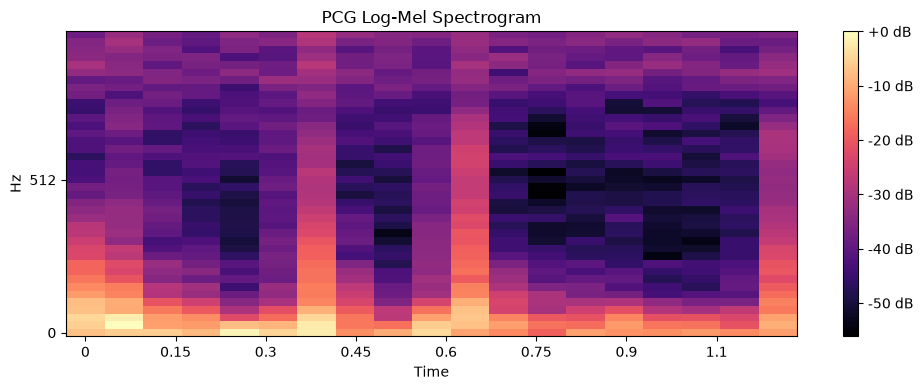

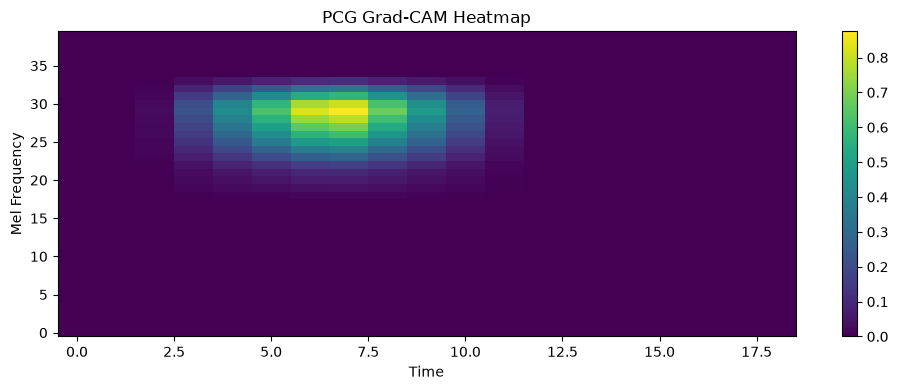

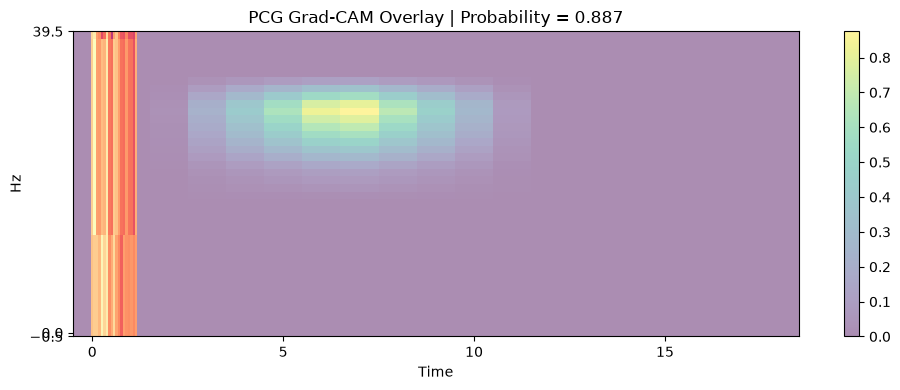

In [45]:
# ============================================================
# PCG GRAD-CAM - REBUILD FUNCTIONAL MODEL FROM TRAINED WEIGHTS
# ============================================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import librosa.display


# ------------------------------------------------------------
# 1. Create a fresh Functional PCG model
#    Same architecture as the trained clean PCG CNN
# ------------------------------------------------------------

grad_input = tf.keras.Input(
    shape=(40, 19, 1),
    name="pcg_input"
)

x = tf.keras.layers.Conv2D(
    32, (3, 3),
    activation="relu",
    padding="same",
    name="gc_conv1"
)(grad_input)

x = tf.keras.layers.BatchNormalization(
    name="gc_bn1"
)(x)

x = tf.keras.layers.MaxPooling2D(
    (2, 2),
    name="gc_pool1"
)(x)

x = tf.keras.layers.Conv2D(
    64, (3, 3),
    activation="relu",
    padding="same",
    name="gc_conv2"
)(x)

x = tf.keras.layers.BatchNormalization(
    name="gc_bn2"
)(x)

x = tf.keras.layers.MaxPooling2D(
    (2, 2),
    name="gc_pool2"
)(x)

# LAST CONVOLUTIONAL LAYER
gradcam_conv_output = tf.keras.layers.Conv2D(
    128, (3, 3),
    activation="relu",
    padding="same",
    name="gc_conv3"
)(x)

x = tf.keras.layers.BatchNormalization(
    name="gc_bn3"
)(gradcam_conv_output)

x = tf.keras.layers.GlobalAveragePooling2D(
    name="gc_gap"
)(x)

x = tf.keras.layers.Dropout(
    0.3,
    name="gc_dropout1"
)(x)

x = tf.keras.layers.Dense(
    64,
    activation="relu",
    name="gc_dense1"
)(x)

x = tf.keras.layers.Dropout(
    0.3,
    name="gc_dropout2"
)(x)

grad_output = tf.keras.layers.Dense(
    1,
    activation="sigmoid",
    name="gc_output"
)(x)

gradcam_full_model = tf.keras.Model(
    inputs=grad_input,
    outputs=grad_output,
    name="PCG_GradCAM_Model"
)


# ------------------------------------------------------------
# 2. Copy trained weights from clean_pcg_model
# ------------------------------------------------------------

# Conv1
gradcam_full_model.get_layer("gc_conv1").set_weights(
    clean_pcg_model.get_layer("conv2d").get_weights()
)

# BatchNorm1
gradcam_full_model.get_layer("gc_bn1").set_weights(
    clean_pcg_model.get_layer("batch_normalization").get_weights()
)

# Conv2
gradcam_full_model.get_layer("gc_conv2").set_weights(
    clean_pcg_model.get_layer("conv2d_1").get_weights()
)

# BatchNorm2
gradcam_full_model.get_layer("gc_bn2").set_weights(
    clean_pcg_model.get_layer("batch_normalization_1").get_weights()
)

# Conv3
gradcam_full_model.get_layer("gc_conv3").set_weights(
    clean_pcg_model.get_layer("conv2d_2").get_weights()
)

# BatchNorm3
gradcam_full_model.get_layer("gc_bn3").set_weights(
    clean_pcg_model.get_layer("batch_normalization_2").get_weights()
)

# Dense 64
gradcam_full_model.get_layer("gc_dense1").set_weights(
    clean_pcg_model.get_layer("dense_2").get_weights()
)

# Final output
gradcam_full_model.get_layer("gc_output").set_weights(
    clean_pcg_model.get_layer("rhd_probability").get_weights()
)

print("Functional Grad-CAM model created.")
print("Weights copied successfully.")


# ------------------------------------------------------------
# 3. Create model that returns:
#    - last convolutional feature maps
#    - final prediction
# ------------------------------------------------------------

gradcam_model = tf.keras.Model(
    inputs=grad_input,
    outputs=[
        gradcam_conv_output,
        grad_output
    ]
)

print("\nGrad-CAM model ready.")
print("Feature-map output:",
      gradcam_conv_output.shape)

print("Prediction output:",
      grad_output.shape)


# ------------------------------------------------------------
# 4. Select one PCG test segment
# ------------------------------------------------------------

sample_index = 0

sample = X_pcg_clean_test_cnn[
    sample_index:sample_index + 1
].astype(np.float32)

true_label = int(
    y_pcg_clean_test[sample_index]
)

print("\nSample shape:", sample.shape)
print("True label:", true_label)


# ------------------------------------------------------------
# 5. Calculate Grad-CAM
# ------------------------------------------------------------

with tf.GradientTape() as tape:

    conv_outputs, predictions = gradcam_model(
        sample,
        training=False
    )

    prediction = predictions[:, 0]

grads = tape.gradient(
    prediction,
    conv_outputs
)

# Remove batch dimension
conv_outputs = conv_outputs[0]
grads = grads[0]

# Average gradient over spatial dimensions
pooled_grads = tf.reduce_mean(
    grads,
    axis=(0, 1)
)

# Weighted feature maps
heatmap = tf.reduce_sum(
    conv_outputs * pooled_grads,
    axis=-1
)

# ReLU
heatmap = tf.maximum(
    heatmap,
    0
)

# Normalize
max_value = tf.reduce_max(heatmap)

if float(max_value) > 0:
    heatmap = heatmap / max_value

heatmap = heatmap.numpy()


# ------------------------------------------------------------
# 6. Prediction
# ------------------------------------------------------------

prediction_probability = float(
    predictions[0, 0]
)

predicted_label = int(
    prediction_probability >= 0.5
)

print("\nPrediction probability:",
      prediction_probability)

print("Predicted label:",
      predicted_label)

print("True label:",
      true_label)

print("Heatmap shape:",
      heatmap.shape)


# ------------------------------------------------------------
# 7. Original spectrogram
# ------------------------------------------------------------

spectrogram = sample[0, :, :, 0]

# Resize Grad-CAM to original spectrogram size
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (
        spectrogram.shape[0],
        spectrogram.shape[1]
    )
).numpy().squeeze()


# ------------------------------------------------------------
# 8. Original PCG spectrogram
# ------------------------------------------------------------

plt.figure(figsize=(10, 4))

librosa.display.specshow(
    spectrogram,
    sr=2000,
    hop_length=128,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(
    format="%+2.0f dB"
)

plt.title(
    "PCG Log-Mel Spectrogram"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Grad-CAM heatmap
# ------------------------------------------------------------

plt.figure(figsize=(10, 4))

plt.imshow(
    heatmap_resized,
    aspect="auto",
    origin="lower"
)

plt.colorbar()

plt.title(
    "PCG Grad-CAM Heatmap"
)

plt.xlabel("Time")
plt.ylabel("Mel Frequency")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Grad-CAM overlay
# ------------------------------------------------------------

plt.figure(figsize=(10, 4))

librosa.display.specshow(
    spectrogram,
    sr=2000,
    hop_length=128,
    x_axis="time",
    y_axis="mel"
)

plt.imshow(
    heatmap_resized,
    aspect="auto",
    origin="lower",
    alpha=0.45
)

plt.colorbar()

plt.title(
    f"PCG Grad-CAM Overlay | "
    f"Probability = {prediction_probability:.3f}"
)

plt.tight_layout()
plt.show()

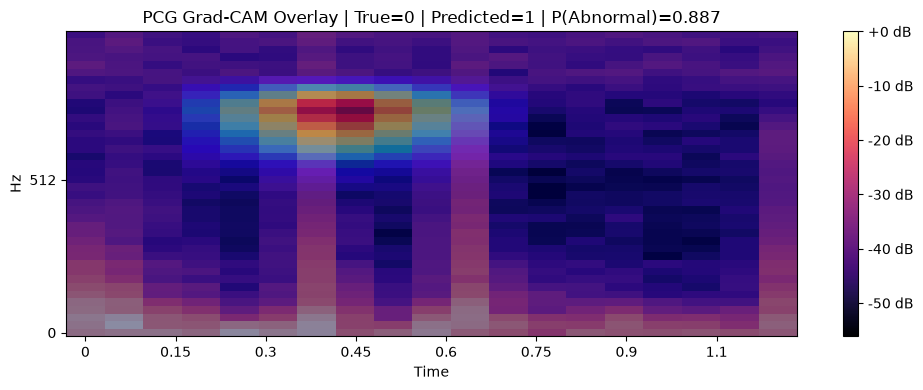

In [46]:
# ============================================================
# CORRECTLY ALIGNED PCG GRAD-CAM OVERLAY
# ============================================================

fig, ax = plt.subplots(figsize=(10, 4))

# Original spectrogram
img = librosa.display.specshow(
    spectrogram,
    sr=2000,
    hop_length=128,
    x_axis="time",
    y_axis="mel",
    ax=ax
)

# Grad-CAM using the SAME spectrogram coordinate system
librosa.display.specshow(
    heatmap_resized,
    sr=2000,
    hop_length=128,
    x_axis="time",
    y_axis="mel",
    cmap="jet",
    alpha=0.45,
    ax=ax
)

fig.colorbar(img, ax=ax, format="%+2.0f dB")

ax.set_title(
    f"PCG Grad-CAM Overlay | "
    f"True={true_label} | "
    f"Predicted={predicted_label} | "
    f"P(Abnormal)={prediction_probability:.3f}"
)

plt.tight_layout()
plt.show()

In [47]:
# ============================================================
# ECG MODEL LAYERS FOR EXPLAINABILITY
# ============================================================

print("Clean ECG model:", clean_ecg_model.name)
print("\nECG model layers:")

for i, layer in enumerate(clean_ecg_model.layers):
    print(i, layer.name, layer.__class__.__name__)

Clean ECG model: sequential_1

ECG model layers:
0 conv1d Conv1D
1 batch_normalization_3 BatchNormalization
2 max_pooling1d MaxPooling1D
3 conv1d_1 Conv1D
4 batch_normalization_4 BatchNormalization
5 max_pooling1d_1 MaxPooling1D
6 conv1d_2 Conv1D
7 batch_normalization_5 BatchNormalization
8 global_average_pooling1d GlobalAveragePooling1D
9 dropout_5 Dropout
10 dense_3 Dense
11 dropout_6 Dropout
12 rhd_probability Dense


In [48]:
# ============================================================
# BUILD FUNCTIONAL ECG MODEL FOR 1D GRAD-CAM
# ============================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Functional input
ecg_grad_input = keras.Input(
    shape=(4000, 1),
    name="ecg_gradcam_input"
)

x = ecg_grad_input

# Same architecture as clean ECG model
x = layers.Conv1D(
    32, 7,
    activation="relu",
    padding="same",
    name="conv1d"
)(x)

x = layers.BatchNormalization(
    name="batch_normalization_3"
)(x)

x = layers.MaxPooling1D(
    2,
    name="max_pooling1d"
)(x)

x = layers.Conv1D(
    64, 5,
    activation="relu",
    padding="same",
    name="conv1d_1"
)(x)

x = layers.BatchNormalization(
    name="batch_normalization_4"
)(x)

x = layers.MaxPooling1D(
    2,
    name="max_pooling1d_1"
)(x)

# Last convolutional layer
ecg_conv_output = layers.Conv1D(
    128, 3,
    activation="relu",
    padding="same",
    name="conv1d_2"
)(x)

x = layers.BatchNormalization(
    name="batch_normalization_5"
)(ecg_conv_output)

x = layers.GlobalAveragePooling1D(
    name="global_average_pooling1d"
)(x)

x = layers.Dropout(
    0.3,
    name="dropout_5"
)(x)

x = layers.Dense(
    64,
    activation="relu",
    name="dense_3"
)(x)

x = layers.Dropout(
    0.3,
    name="dropout_6"
)(x)

ecg_output = layers.Dense(
    1,
    activation="sigmoid",
    name="rhd_probability"
)(x)

# Create Functional model
ecg_grad_model = keras.Model(
    inputs=ecg_grad_input,
    outputs=[ecg_conv_output, ecg_output],
    name="ECG_GradCAM_Model"
)

# ------------------------------------------------------------
# COPY TRAINED WEIGHTS BY LAYER NAME
# ------------------------------------------------------------

original_layers = {
    layer.name: layer
    for layer in clean_ecg_model.layers
}

copied_layers = []

for new_layer in ecg_grad_model.layers:

    if new_layer.name in original_layers:

        old_layer = original_layers[new_layer.name]

        if new_layer.weights and old_layer.weights:

            new_layer.set_weights(
                old_layer.get_weights()
            )

            copied_layers.append(new_layer.name)

print("Functional ECG Grad-CAM model created.")
print("Weights copied successfully.")

print("\nCopied layers:")
for name in copied_layers:
    print("-", name)

print("\nFeature-map output:", ecg_grad_model.output[0].shape)
print("Prediction output:", ecg_grad_model.output[1].shape)

Functional ECG Grad-CAM model created.
Weights copied successfully.

Copied layers:
- conv1d
- batch_normalization_3
- conv1d_1
- batch_normalization_4
- conv1d_2
- batch_normalization_5
- dense_3
- rhd_probability

Feature-map output: (None, 1000, 128)
Prediction output: (None, 1)


In [49]:
# ============================================================
# VERIFY ORIGINAL ECG MODEL VS GRAD-CAM MODEL
# ============================================================

# Take one ECG sample from the clean test set
sample_ecg = X_ecg_clean_test_cnn[0:1]

# Original ECG model prediction
original_probability = clean_ecg_model.predict(
    sample_ecg,
    verbose=0
)[0][0]

# Functional Grad-CAM model prediction
_, gradcam_probability = ecg_grad_model.predict(
    sample_ecg,
    verbose=0
)

gradcam_probability = gradcam_probability[0][0]

print("Original ECG model probability :", original_probability)
print("Grad-CAM model probability     :", gradcam_probability)

print(
    "Absolute difference             :",
    abs(original_probability - gradcam_probability)
)

# Predicted class from the original model
print(
    "Predicted label                 :",
    int(original_probability >= 0.5)
)

Original ECG model probability : 0.4096055
Grad-CAM model probability     : 0.4096055
Absolute difference             : 0.0
Predicted label                 : 0


In [50]:
# ============================================================
# GENERATE ECG 1D GRAD-CAM
# ============================================================

# Sample ECG
sample_ecg = X_ecg_clean_test_cnn[0:1]

# Convert to TensorFlow tensor
sample_tensor = tf.convert_to_tensor(
    sample_ecg,
    dtype=tf.float32
)

# Gradient computation
with tf.GradientTape() as tape:

    # Get convolutional feature maps and prediction
    conv_output, prediction = ecg_grad_model(
        sample_tensor,
        training=False
    )

    # Probability of abnormal class
    abnormal_probability = prediction[:, 0]

# Gradient of prediction with respect to feature maps
gradients = tape.gradient(
    abnormal_probability,
    conv_output
)

# Global average pooling of gradients
pooled_gradients = tf.reduce_mean(
    gradients,
    axis=1
)

# Weight each feature map by its gradient importance
weighted_features = (
    conv_output *
    pooled_gradients[:, tf.newaxis, :]
)

# Combine feature maps
cam = tf.reduce_sum(
    weighted_features,
    axis=-1
)

# ReLU: keep only positive influence
cam = tf.maximum(cam, 0)

# Normalize to 0–1
cam = cam / (
    tf.reduce_max(cam, axis=1, keepdims=True) + 1e-8
)

ecg_heatmap = cam.numpy()[0]

print("ECG Grad-CAM generated.")
print("ECG sample shape:", sample_ecg.shape)
print("Feature-map shape:", conv_output.shape)
print("Heatmap shape:", ecg_heatmap.shape)
print("Prediction probability:", float(abnormal_probability.numpy()[0]))
print("Predicted label:", int(abnormal_probability.numpy()[0] >= 0.5))

ECG Grad-CAM generated.
ECG sample shape: (1, 4000, 1)
Feature-map shape: (1, 1000, 128)
Heatmap shape: (1000,)
Prediction probability: 0.4096055030822754
Predicted label: 0


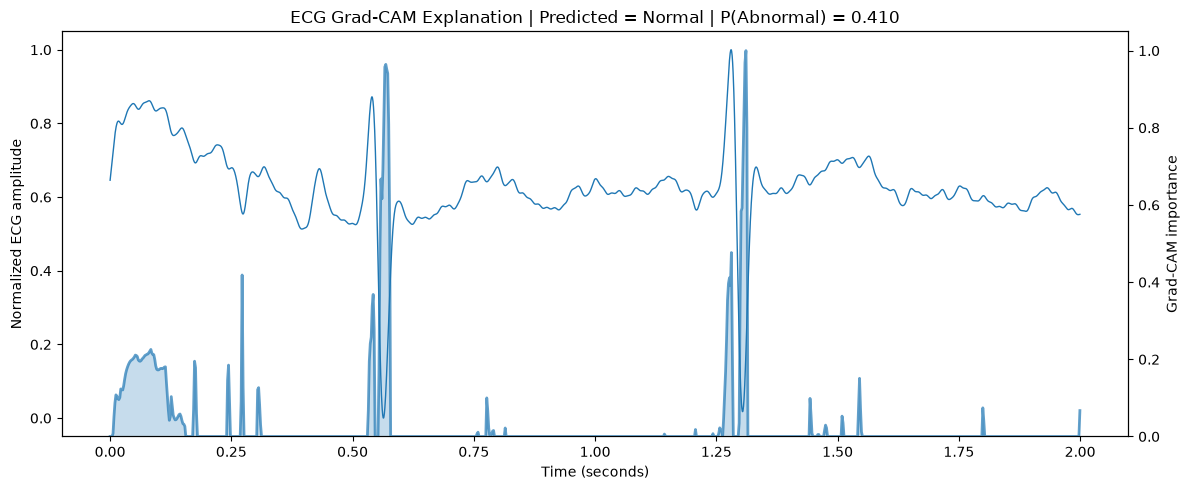

In [51]:
# ============================================================
# VISUALIZE ECG WAVEFORM + GRAD-CAM
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Original ECG signal
ecg_signal = sample_ecg[0, :, 0]

# Original ECG has 4000 samples at 2000 Hz
sample_rate_ecg = 2000

# Time axis for ECG
time_ecg = np.arange(len(ecg_signal)) / sample_rate_ecg

# Grad-CAM heatmap has 1000 points
# Map it back to the original 4000-sample timeline
heatmap_time = np.linspace(
    0,
    time_ecg[-1],
    len(ecg_heatmap)
)

# Normalize ECG for clearer visualization
ecg_min = ecg_signal.min()
ecg_max = ecg_signal.max()

ecg_normalized = (
    (ecg_signal - ecg_min) /
    (ecg_max - ecg_min + 1e-8)
)

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, ax1 = plt.subplots(figsize=(12, 5))

# ECG waveform
ax1.plot(
    time_ecg,
    ecg_normalized,
    linewidth=1
)

ax1.set_xlabel("Time (seconds)")
ax1.set_ylabel("Normalized ECG amplitude")

ax1.set_title(
    f"ECG Grad-CAM Explanation | "
    f"Predicted = {'Abnormal' if abnormal_probability.numpy()[0] >= 0.5 else 'Normal'} | "
    f"P(Abnormal) = {abnormal_probability.numpy()[0]:.3f}"
)

# ------------------------------------------------------------
# GRAD-CAM IMPORTANCE
# ------------------------------------------------------------

ax2 = ax1.twinx()

ax2.plot(
    heatmap_time,
    ecg_heatmap,
    linewidth=2,
    alpha=0.7
)

ax2.fill_between(
    heatmap_time,
    ecg_heatmap,
    alpha=0.25
)

ax2.set_ylabel("Grad-CAM importance")
ax2.set_ylim(0, 1.05)

plt.tight_layout()
plt.show()

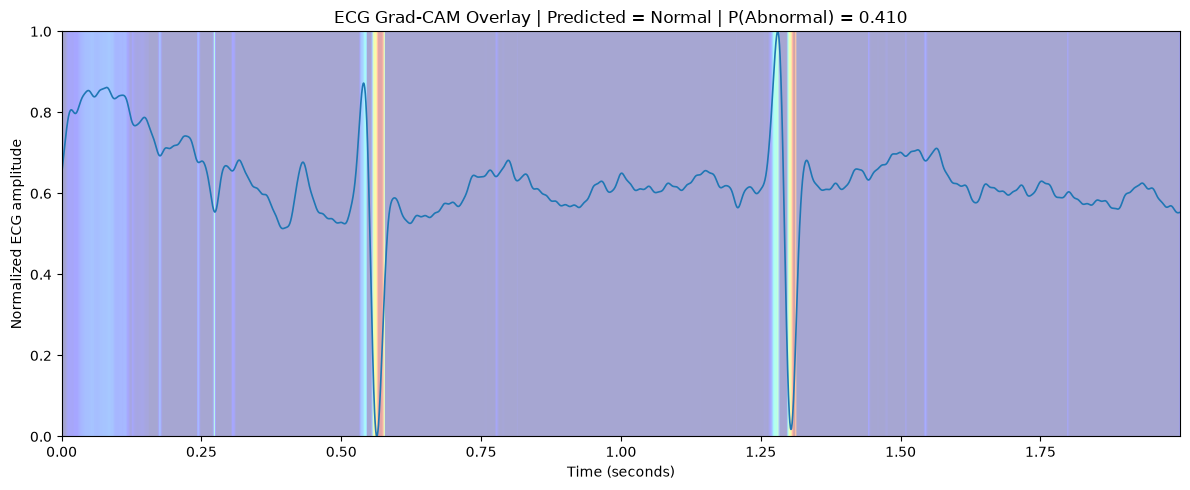

In [52]:
# ============================================================
# ECG GRAD-CAM OVERLAY - REPORT/PPT VERSION
# ============================================================

fig, ax = plt.subplots(figsize=(12, 5))

# ECG waveform
ax.plot(
    time_ecg,
    ecg_normalized,
    linewidth=1.2,
    zorder=2
)

# Grad-CAM as a background heatmap
heatmap_2d = np.tile(
    ecg_heatmap,
    (80, 1)
)

ax.imshow(
    heatmap_2d,
    extent=[
        time_ecg[0],
        time_ecg[-1],
        0,
        1
    ],
    aspect="auto",
    origin="lower",
    cmap="jet",
    alpha=0.35,
    zorder=1
)

ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Normalized ECG amplitude")

predicted_class = (
    "Abnormal"
    if abnormal_probability.numpy()[0] >= 0.5
    else "Normal"
)

ax.set_title(
    f"ECG Grad-CAM Overlay | "
    f"Predicted = {predicted_class} | "
    f"P(Abnormal) = {abnormal_probability.numpy()[0]:.3f}"
)

plt.tight_layout()
plt.show()

In [53]:
# ============================================================
# FIND AN ECG FALSE-POSITIVE RECORDING
# ============================================================

# Get segment-level predictions from the clean ECG model
ecg_test_segment_prob = clean_ecg_model.predict(
    X_ecg_clean_test_cnn,
    verbose=0
).ravel()

# Find the metadata variable automatically
candidate_metadata = [
    name for name in globals()
    if "ecg" in name.lower() and "metadata" in name.lower()
]

print("Possible ECG metadata variables:")
print(candidate_metadata)

Possible ECG metadata variables:
['ECG_METADATA_PATH', 'ecg_metadata', 'ecg_val_metadata_clean', 'ecg_test_metadata_clean']


In [54]:
# ============================================================
# FIND ECG FALSE-POSITIVE RECORDING
# ============================================================

# Copy test metadata
ecg_fp_df = ecg_test_metadata_clean.copy()

# Add segment-level probabilities
ecg_fp_df["probability"] = ecg_test_segment_prob

# Aggregate predictions at recording level
ecg_recording_predictions = (
    ecg_fp_df
    .groupby("recording_id")
    .agg(
        true_label=("label", "first"),
        predicted_probability=("probability", "mean"),
        num_segments=("probability", "count")
    )
    .reset_index()
)

# Validation-selected threshold
ecg_threshold = 0.6458540558815002

# Find false positives:
# True = Normal (0)
# Predicted = Abnormal (probability >= threshold)
ecg_false_positives = ecg_recording_predictions[
    (ecg_recording_predictions["true_label"] == -1) &
    (ecg_recording_predictions["predicted_probability"] >= ecg_threshold)
].copy()

print("ECG false-positive recordings:", len(ecg_false_positives))

print("\nFalse-positive examples:")
print(
    ecg_false_positives.sort_values(
        "predicted_probability",
        ascending=False
    ).head(10).to_string(index=False)
)

ECG false-positive recordings: 7

False-positive examples:
recording_id  true_label  predicted_probability  num_segments
       a0227          -1               0.918229            15
       a0208          -1               0.748454            16
       a0385          -1               0.740301            10
       a0301          -1               0.728028            15
       a0323          -1               0.695569            10
       a0386          -1               0.666522            18
       a0102          -1               0.655302            17


In [55]:
# ============================================================
# SELECT STRONGEST ECG FALSE-POSITIVE SEGMENT
# ============================================================

# Recording selected for XAI
selected_recording = "a0227"

# Find all segments belonging to this recording
recording_mask = (
    ecg_test_metadata_clean["recording_id"] == selected_recording
)

# Segment probabilities for this recording
recording_segment_probs = ecg_test_segment_prob[recording_mask.values]

# Find the segment with highest abnormal probability
local_best_index = np.argmax(recording_segment_probs)

# Convert local index to actual test-array index
global_indices = np.where(recording_mask.values)[0]
selected_index = global_indices[local_best_index]

# Select ECG segment
sample_ecg_fp = X_ecg_clean_test_cnn[selected_index:selected_index + 1]

# Prediction
fp_probability = clean_ecg_model.predict(
    sample_ecg_fp,
    verbose=0
)[0][0]

# Print information
print("Selected recording:", selected_recording)
print("True label:", -1, "(Normal)")
print("Number of segments:", len(recording_segment_probs))
print("Selected segment index:", selected_index)
print("Segment abnormal probability:", fp_probability)
print("Predicted label:", int(fp_probability >= 0.5))

Selected recording: a0227
True label: -1 (Normal)
Number of segments: 15
Selected segment index: 498
Segment abnormal probability: 0.970243
Predicted label: 1


In [56]:
# ============================================================
# ECG GRAD-CAM FOR FALSE-POSITIVE RECORDING a0227
# ============================================================

sample_tensor_fp = tf.convert_to_tensor(
    sample_ecg_fp,
    dtype=tf.float32
)

with tf.GradientTape() as tape:
    conv_output_fp, prediction_fp = ecg_grad_model(
        sample_tensor_fp,
        training=False
    )

    abnormal_score_fp = prediction_fp[:, 0]

gradients_fp = tape.gradient(
    abnormal_score_fp,
    conv_output_fp
)

pooled_gradients_fp = tf.reduce_mean(
    gradients_fp,
    axis=1
)

weighted_features_fp = (
    conv_output_fp *
    pooled_gradients_fp[:, tf.newaxis, :]
)

cam_fp = tf.reduce_sum(
    weighted_features_fp,
    axis=-1
)

cam_fp = tf.maximum(cam_fp, 0)

cam_fp = cam_fp / (
    tf.reduce_max(cam_fp, axis=1, keepdims=True) + 1e-8
)

ecg_heatmap_fp = cam_fp.numpy()[0]

print("False-positive ECG Grad-CAM generated.")
print("Recording:", selected_recording)
print("True label: Normal")
print("Segment abnormal probability:", float(abnormal_score_fp.numpy()[0]))
print("Heatmap shape:", ecg_heatmap_fp.shape)

False-positive ECG Grad-CAM generated.
Recording: a0227
True label: Normal
Segment abnormal probability: 0.970242977142334
Heatmap shape: (1000,)


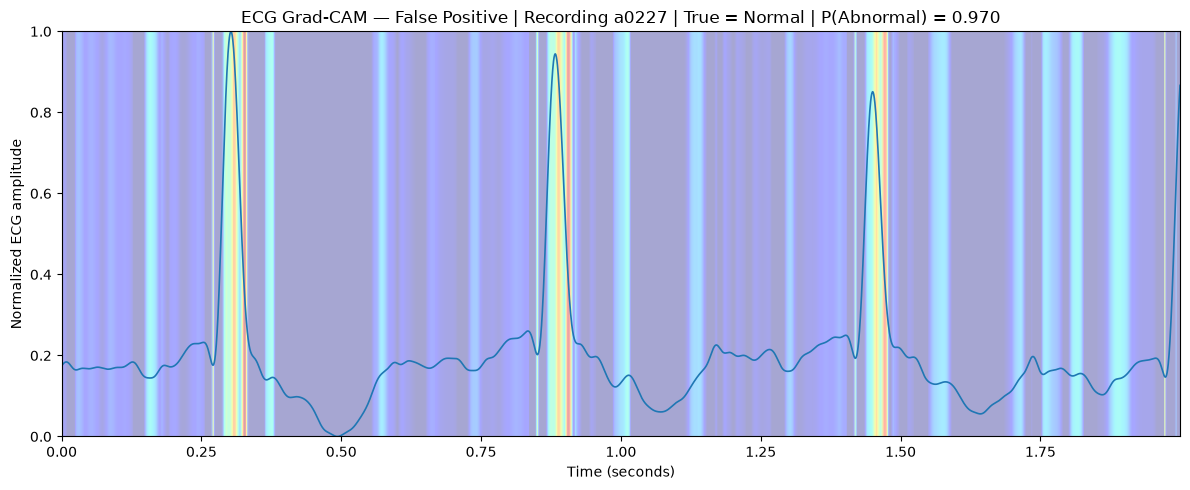

In [57]:
# ============================================================
# FALSE-POSITIVE ECG GRAD-CAM OVERLAY
# ============================================================

ecg_signal_fp = sample_ecg_fp[0, :, 0]
time_ecg_fp = np.arange(len(ecg_signal_fp)) / 2000

# Normalize waveform for display only
ecg_normalized_fp = (
    (ecg_signal_fp - ecg_signal_fp.min()) /
    (ecg_signal_fp.max() - ecg_signal_fp.min() + 1e-8)
)

# Expand Grad-CAM timeline to the ECG sample timeline
heatmap_time_fp = np.linspace(
    time_ecg_fp[0],
    time_ecg_fp[-1],
    len(ecg_heatmap_fp)
)

heatmap_2d_fp = np.tile(ecg_heatmap_fp, (80, 1))

fig, ax = plt.subplots(figsize=(12, 5))

ax.imshow(
    heatmap_2d_fp,
    extent=[time_ecg_fp[0], time_ecg_fp[-1], 0, 1],
    aspect="auto",
    origin="lower",
    cmap="jet",
    alpha=0.35,
    zorder=1
)

ax.plot(
    time_ecg_fp,
    ecg_normalized_fp,
    linewidth=1.2,
    zorder=2
)

ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Normalized ECG amplitude")
ax.set_title(
    f"ECG Grad-CAM — False Positive | Recording {selected_recording} | "
    f"True = Normal | P(Abnormal) = {float(abnormal_score_fp.numpy()[0]):.3f}"
)

plt.tight_layout()
plt.show()

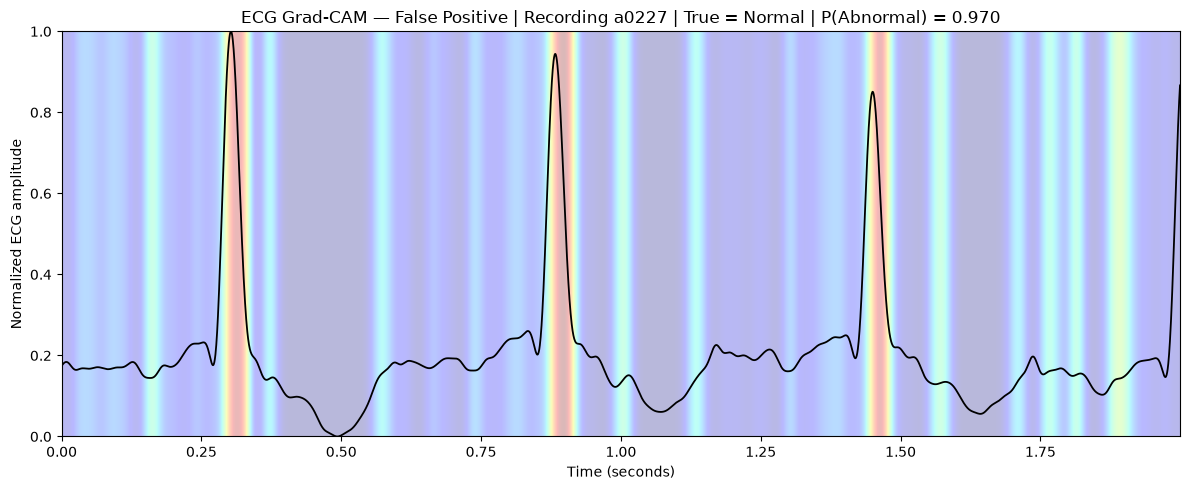

In [58]:
# ============================================================
# SMOOTHED ECG GRAD-CAM OVERLAY FOR VISUALIZATION
# ============================================================

from scipy.ndimage import gaussian_filter1d

# Smooth the heatmap for display only
ecg_heatmap_fp_smooth = gaussian_filter1d(
    ecg_heatmap_fp,
    sigma=5
)

# Normalize the smoothed display heatmap
ecg_heatmap_fp_smooth = (
    ecg_heatmap_fp_smooth /
    (ecg_heatmap_fp_smooth.max() + 1e-8)
)

# Repeat across the plot height
heatmap_2d_fp_smooth = np.tile(
    ecg_heatmap_fp_smooth,
    (80, 1)
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.imshow(
    heatmap_2d_fp_smooth,
    extent=[
        time_ecg_fp[0],
        time_ecg_fp[-1],
        0,
        1
    ],
    aspect="auto",
    origin="lower",
    cmap="jet",
    alpha=0.28,
    interpolation="bilinear",
    zorder=1
)

ax.plot(
    time_ecg_fp,
    ecg_normalized_fp,
    linewidth=1.3,
    color="black",
    zorder=2
)

ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Normalized ECG amplitude")

ax.set_title(
    f"ECG Grad-CAM — False Positive | "
    f"Recording {selected_recording} | "
    f"True = Normal | "
    f"P(Abnormal) = {float(abnormal_score_fp.numpy()[0]):.3f}"
)

plt.tight_layout()
plt.show()

In [59]:
# ============================================================
# FIND A CORRECTLY CLASSIFIED ABNORMAL ECG RECORDING
# ============================================================

ecg_correct_abnormal = ecg_recording_predictions[
    (ecg_recording_predictions["true_label"] == 1) &
    (ecg_recording_predictions["predicted_probability"] >= ecg_threshold)
].copy()

ecg_correct_abnormal = ecg_correct_abnormal.sort_values(
    "predicted_probability",
    ascending=False
)

print("Correctly classified abnormal recordings:",
      len(ecg_correct_abnormal))

print(
    ecg_correct_abnormal.head(10).to_string(index=False)
)

Correctly classified abnormal recordings: 32
recording_id  true_label  predicted_probability  num_segments
       a0062           1               0.974797            18
       a0261           1               0.968353            17
       a0044           1               0.964145            15
       a0348           1               0.962378            18
       a0236           1               0.949460            18
       a0147           1               0.949273            17
       a0052           1               0.938317            17
       a0043           1               0.930308            17
       a0089           1               0.921832            10
       a0180           1               0.918705            18


In [60]:
# ============================================================
# SELECT A CORRECTLY CLASSIFIED ABNORMAL ECG SEGMENT
# ============================================================

selected_abnormal_recording = "a0261"

# Locate segments from this recording
abnormal_mask = (
    ecg_test_metadata_clean["recording_id"]
    == selected_abnormal_recording
)

# Get the segment-level probabilities
abnormal_segment_probs = ecg_test_segment_prob[
    abnormal_mask.values
]

# Select the segment with the highest abnormal probability
local_best_index = np.argmax(abnormal_segment_probs)

global_indices = np.where(abnormal_mask.values)[0]
selected_abnormal_index = global_indices[local_best_index]

# Extract the ECG segment
sample_ecg_abnormal = X_ecg_clean_test_cnn[
    selected_abnormal_index:selected_abnormal_index + 1
]

# Predict with the original clean ECG model
abnormal_segment_probability = clean_ecg_model.predict(
    sample_ecg_abnormal,
    verbose=0
)[0][0]

print("Selected recording:", selected_abnormal_recording)
print("True label: 1 (Abnormal)")
print("Number of segments:", len(abnormal_segment_probs))
print("Selected segment index:", selected_abnormal_index)
print(
    "Segment abnormal probability:",
    float(abnormal_segment_probability)
)
print(
    "Predicted label:",
    int(abnormal_segment_probability >= 0.5)
)

Selected recording: a0261
True label: 1 (Abnormal)
Number of segments: 17
Selected segment index: 538
Segment abnormal probability: 0.987634539604187
Predicted label: 1


In [61]:
# ============================================================
# ECG GRAD-CAM FOR CORRECTLY CLASSIFIED ABNORMAL SEGMENT
# ============================================================

sample_tensor_abnormal = tf.convert_to_tensor(
    sample_ecg_abnormal,
    dtype=tf.float32
)

with tf.GradientTape() as tape:
    conv_output_abnormal, prediction_abnormal = ecg_grad_model(
        sample_tensor_abnormal,
        training=False
    )

    abnormal_score = prediction_abnormal[:, 0]

gradients_abnormal = tape.gradient(
    abnormal_score,
    conv_output_abnormal
)

pooled_gradients_abnormal = tf.reduce_mean(
    gradients_abnormal,
    axis=1
)

weighted_features_abnormal = (
    conv_output_abnormal
    * pooled_gradients_abnormal[:, tf.newaxis, :]
)

cam_abnormal = tf.reduce_sum(
    weighted_features_abnormal,
    axis=-1
)

cam_abnormal = tf.maximum(cam_abnormal, 0)

cam_abnormal = cam_abnormal / (
    tf.reduce_max(cam_abnormal, axis=1, keepdims=True) + 1e-8
)

ecg_heatmap_abnormal = cam_abnormal.numpy()[0]

print("Abnormal ECG Grad-CAM generated.")
print("Recording:", selected_abnormal_recording)
print(
    "Abnormal probability:",
    float(abnormal_score.numpy()[0])
)
print("Heatmap shape:", ecg_heatmap_abnormal.shape)

Abnormal ECG Grad-CAM generated.
Recording: a0261
Abnormal probability: 0.987634539604187
Heatmap shape: (1000,)


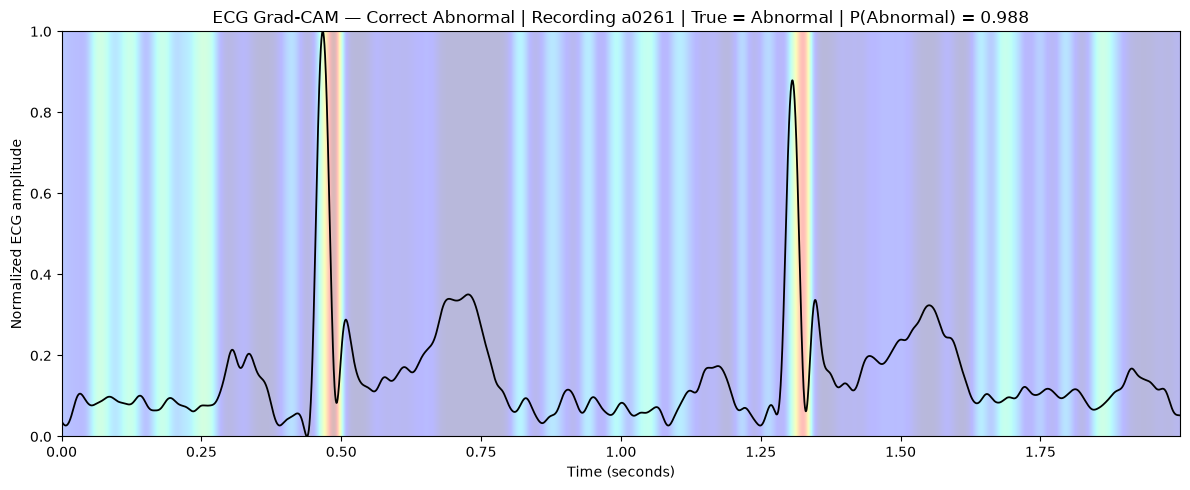

In [62]:
# ============================================================
# ECG GRAD-CAM OVERLAY — CORRECTLY CLASSIFIED ABNORMAL
# ============================================================

from scipy.ndimage import gaussian_filter1d

ecg_signal_abnormal = sample_ecg_abnormal[0, :, 0]
time_ecg_abnormal = np.arange(len(ecg_signal_abnormal)) / 2000

# Normalize the waveform for display only
ecg_normalized_abnormal = (
    (ecg_signal_abnormal - ecg_signal_abnormal.min()) /
    (ecg_signal_abnormal.max() - ecg_signal_abnormal.min() + 1e-8)
)

# Smooth Grad-CAM only for visualization
heatmap_abnormal_smooth = gaussian_filter1d(
    ecg_heatmap_abnormal,
    sigma=5
)
heatmap_abnormal_smooth /= (
    heatmap_abnormal_smooth.max() + 1e-8
)

heatmap_2d_abnormal = np.tile(
    heatmap_abnormal_smooth,
    (80, 1)
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.imshow(
    heatmap_2d_abnormal,
    extent=[
        time_ecg_abnormal[0],
        time_ecg_abnormal[-1],
        0,
        1
    ],
    aspect="auto",
    origin="lower",
    cmap="jet",
    alpha=0.28,
    interpolation="bilinear",
    zorder=1
)

ax.plot(
    time_ecg_abnormal,
    ecg_normalized_abnormal,
    linewidth=1.3,
    color="black",
    zorder=2
)

ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Normalized ECG amplitude")

ax.set_title(
    f"ECG Grad-CAM — Correct Abnormal | "
    f"Recording {selected_abnormal_recording} | "
    f"True = Abnormal | "
    f"P(Abnormal) = {float(abnormal_score.numpy()[0]):.3f}"
)

plt.tight_layout()
plt.show()

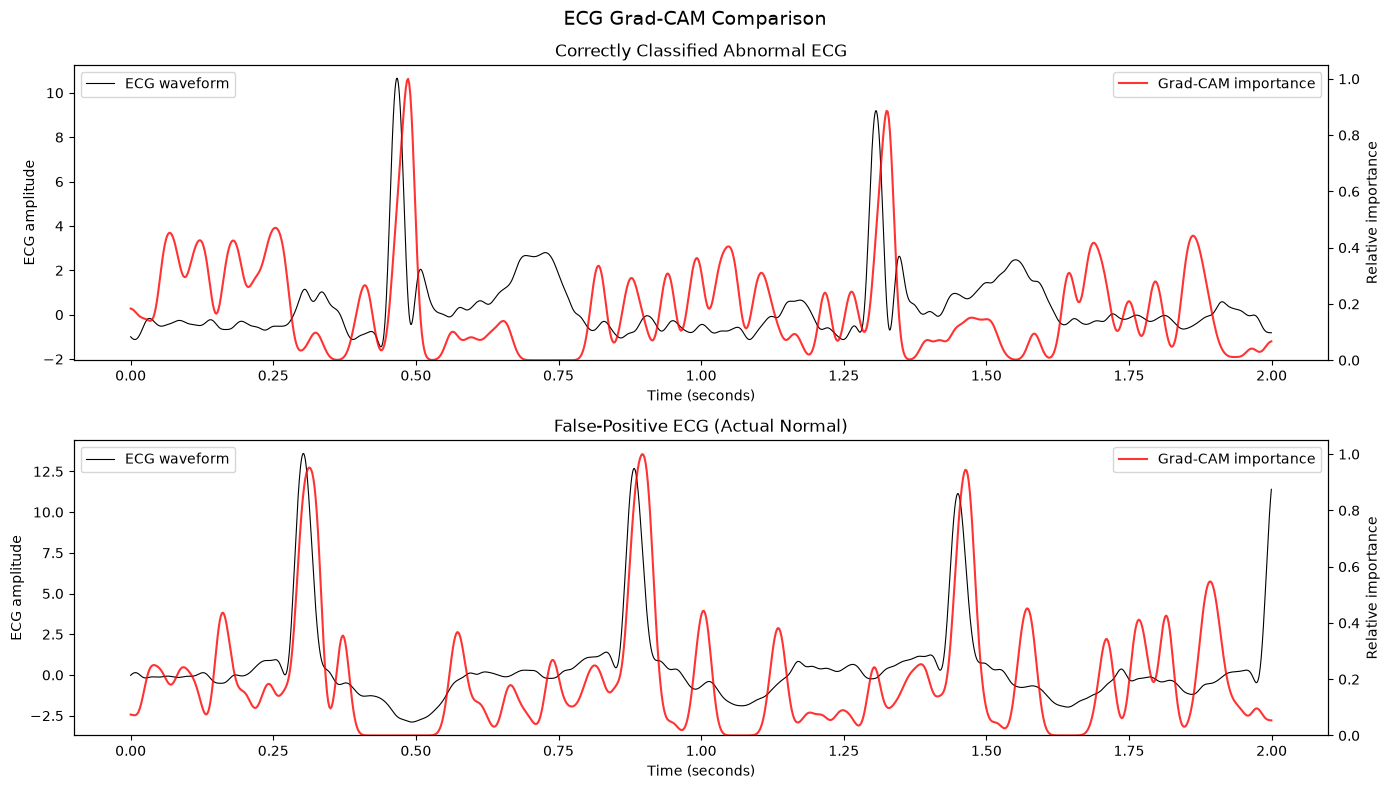

In [63]:

# Cell 16: Compare ECG Grad-CAM examples

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# Verify that the previous cells have created the required variables
required_vars = [
    "sample_ecg_abnormal",
    "ecg_heatmap_abnormal",
    "sample_ecg_fp",
    "ecg_heatmap_fp"
]

missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    print("Please run the earlier Grad-CAM cells first.")
    print("Missing variables:", missing_vars)

else:
    examples = [
        (
            "Correctly Classified Abnormal ECG",
            sample_ecg_abnormal,
            ecg_heatmap_abnormal
        ),
        (
            "False-Positive ECG (Actual Normal)",
            sample_ecg_fp,
            ecg_heatmap_fp
        )
    ]

    fig, axes = plt.subplots(2, 1, figsize=(14, 8))

    for ax, (title, sample, heatmap) in zip(axes, examples):
        ecg = np.asarray(sample)[0, :, 0]
        heatmap = np.asarray(heatmap).reshape(-1)

        time_ecg = np.arange(len(ecg)) / 2000
        time_heatmap = np.linspace(
            time_ecg[0], time_ecg[-1], len(heatmap)
        )

        smooth_map = gaussian_filter1d(heatmap, sigma=5)
        smooth_map = smooth_map / (smooth_map.max() + 1e-8)

        ax.plot(time_ecg, ecg, color="black",
                linewidth=0.8, label="ECG waveform")

        ax2 = ax.twinx()
        ax2.plot(time_heatmap, smooth_map,
                 color="red", alpha=0.8,
                 label="Grad-CAM importance")
        ax2.set_ylim(0, 1.05)
        ax2.set_ylabel("Relative importance")

        ax.set_title(title)
        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("ECG amplitude")
        ax.legend(loc="upper left")
        ax2.legend(loc="upper right")

    plt.suptitle("ECG Grad-CAM Comparison", fontsize=14)
    plt.tight_layout()
    plt.show()


In [64]:
# Cell 17: Find variables for evaluation plots

keywords = [
    "y_test", "y_true", "y_pred", "prob", "threshold",
    "fusion", "metadata", "test_label", "test_prob",
    "pcg_test", "ecg_test"
]

matches = [
    name for name in globals()
    if any(word in name.lower() for word in keywords)
    and not name.startswith("_")
]

print("Potential evaluation variables:\n")

for name in sorted(matches):
    value = globals()[name]

    if hasattr(value, "shape"):
        print(f"{name}: shape={value.shape}")
    elif isinstance(value, (int, float, str, bool)):
        print(f"{name}: {value}")
    else:
        print(f"{name}: type={type(value).__name__}")

Potential evaluation variables:

ECG_METADATA_PATH: ../processed/ECG/ecg_metadata.csv
PCG_METADATA_PATH: ../processed/PCG/pcg_metadata.csv
X_ecg_fusion_test: shape=(61, 64)
X_ecg_fusion_train: shape=(283, 64)
X_ecg_fusion_val: shape=(61, 64)
X_ecg_test: shape=(960, 4000)
X_ecg_test_cnn: shape=(960, 4000, 1)
X_pcg_fusion_test: shape=(61, 64)
X_pcg_fusion_train: shape=(283, 64)
X_pcg_fusion_val: shape=(61, 64)
X_pcg_test: shape=(1621, 40, 19)
X_pcg_test_cnn: shape=(1621, 40, 19, 1)
abnormal_probability: shape=(1,)
abnormal_segment_probability: shape=()
abnormal_segment_probs: shape=(17,)
best_threshold: shape=()
best_threshold_fusion: shape=()
candidate_metadata: type=list
cm_fusion: shape=(2, 2)
confusion_matrix: type=function
early_stopping_fusion: type=EarlyStopping
ecg_clean_test_prob: shape=(960,)
ecg_clean_threshold: shape=()
ecg_clean_val_prob: shape=(975,)
ecg_metadata: shape=(6360, 7)
ecg_test_mask: shape=(6360,)
ecg_test_metadata_clean: shape=(960, 2)
ecg_test_prediction_df: sh

PCG-ECG Fusion Model: Test Evaluation
----------------------------------------
Test recordings: 61
Threshold:      0.4031
ROC-AUC:        0.8295
Accuracy:       0.7541
Precision:      0.8333
Sensitivity:    0.8140
Specificity:    0.6111
F1-score:       0.8235

Confusion matrix:
[[11  7]
 [ 8 35]]


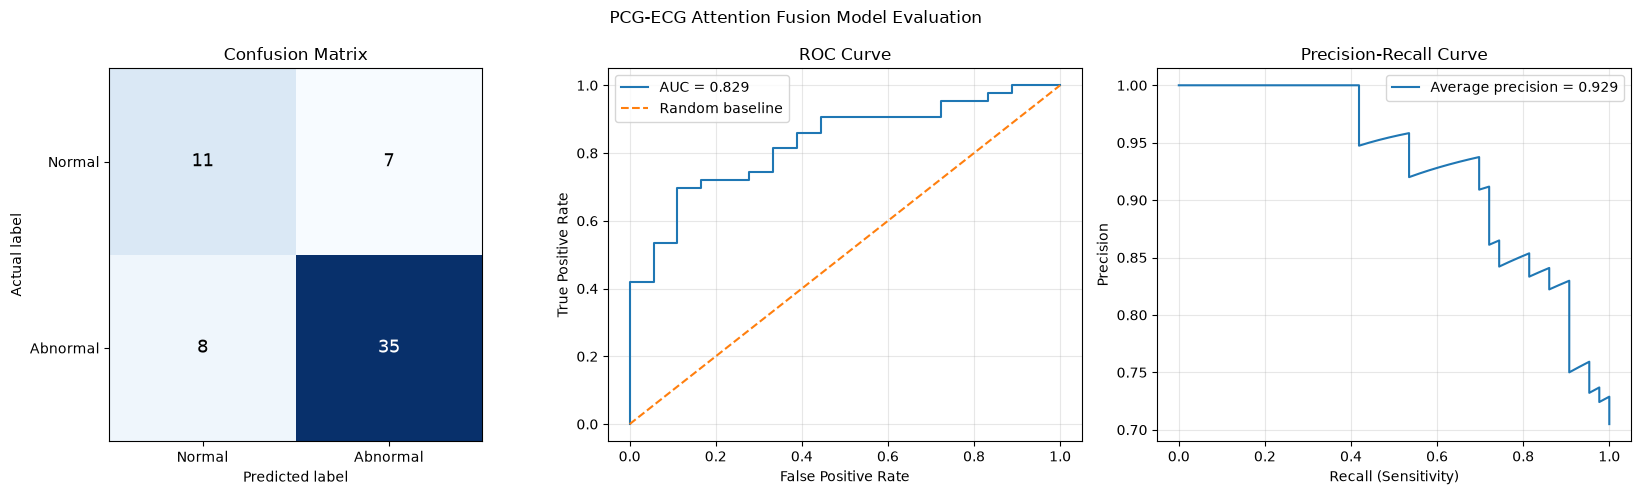

In [66]:

# Cell 18: Evaluate the PCG-ECG fusion model
# Matplotlib-only version (no seaborn required)

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Test labels and predicted probabilities
y_true = np.asarray(y_fusion_test).astype(int).ravel()
y_prob = np.asarray(fusion_test_probabilities).ravel()

# Threshold selected using validation data
threshold = float(best_threshold_fusion)

assert len(y_true) == len(y_prob), "Labels and probabilities do not match"
assert np.isfinite(y_prob).all(), "Probabilities contain invalid values"

y_pred = (y_prob >= threshold).astype(int)

# Calculate evaluation metrics
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
auc = roc_auc_score(y_true, y_prob)
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
sensitivity = recall_score(y_true, y_pred, zero_division=0)
specificity = cm[0, 0] / max(cm[0].sum(), 1)
f1 = f1_score(y_true, y_pred, zero_division=0)

print("PCG-ECG Fusion Model: Test Evaluation")
print("-" * 40)
print(f"Test recordings: {len(y_true)}")
print(f"Threshold:      {threshold:.4f}")
print(f"ROC-AUC:        {auc:.4f}")
print(f"Accuracy:       {accuracy:.4f}")
print(f"Precision:      {precision:.4f}")
print(f"Sensitivity:    {sensitivity:.4f}")
print(f"Specificity:    {specificity:.4f}")
print(f"F1-score:       {f1:.4f}")
print("\nConfusion matrix:")
print(cm)

# ROC and precision-recall curves
fpr, tpr, _ = roc_curve(y_true, y_prob)
pr_precision, pr_recall, _ = precision_recall_curve(y_true, y_prob)
ap = average_precision_score(y_true, y_prob)

# Plot evaluation figures
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Confusion matrix
axes[0].imshow(cm, interpolation="nearest", cmap="Blues")
axes[0].set_title("Confusion Matrix")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("Actual label")
axes[0].set_xticks([0, 1], labels=["Normal", "Abnormal"])
axes[0].set_yticks([0, 1], labels=["Normal", "Abnormal"])

for i in range(2):
    for j in range(2):
        axes[0].text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
            fontsize=13
        )

# 2. ROC curve
axes[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
axes[1].set_title("ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()
axes[1].grid(alpha=0.3)

# 3. Precision-recall curve
axes[2].plot(
    pr_recall, pr_precision,
    label=f"Average precision = {ap:.3f}"
)
axes[2].set_title("Precision-Recall Curve")
axes[2].set_xlabel("Recall (Sensitivity)")
axes[2].set_ylabel("Precision")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle("PCG-ECG Attention Fusion Model Evaluation")
plt.tight_layout()
plt.show()


PCG–ECG Attention Fusion · 61 test recordings
ROC-AUC
0.8295

Accuracy
75.41%

Sensitivity
81.40%

Specificity
61.11%

Precision
83.33%

F1-score
82.35%



The confusion matrix means:
- 11 normal recordings correctly classified as normal.
- 7 normal recordings incorrectly classified as abnormal.
- 8 abnormal recordings incorrectly classified as normal.
- 35 abnormal recordings correctly classified as abnormal.

The ROC curve shows how well the model separates the two classes across different thresholds. The precision–recall curve illustrates the trade-off between precision and sensitivity.
Important: These results are for binary normal/abnormal classification on this test split, not a clinically validated diagnosis of rheumatic heart disease. The current run's threshold is 0.4031; use that value alongside these metrics when documenting this run.

In [67]:
# Cell 19: Inspect individual-model evaluation metrics

metric_names = [
    "test_auc_pcg", "test_accuracy_pcg",
    "test_precision_pcg", "test_sensitivity_pcg",
    "test_specificity_pcg", "test_f1_pcg",
    "test_auc_ecg", "test_accuracy_ecg",
    "test_precision_ecg", "test_sensitivity_ecg",
    "test_specificity_ecg", "test_f1_ecg",
    "pcg_clean_threshold", "ecg_clean_threshold",
    "best_threshold_fusion"
]

for name in metric_names:
    if name in globals():
        print(f"{name} = {globals()[name]}")

test_auc_ecg = 0.8023255813953487
test_accuracy_ecg = 0.6885245901639344
test_precision_ecg = 0.8529411764705882
test_sensitivity_ecg = 0.6744186046511628
test_specificity_ecg = 0.7222222222222222
test_f1_ecg = 0.7532467532467533
pcg_clean_threshold = 0.2101626694202423
ecg_clean_threshold = 0.6912363767623901
best_threshold_fusion = 0.4031279981136322


In [68]:
# Cell 20: Find PCG test evaluation metrics

for name in sorted(globals()):
    if (
        "pcg" in name.lower()
        and any(word in name.lower() for word in [
            "auc", "accuracy", "precision",
            "sensitivity", "specificity", "f1"
        ])
    ):
        value = globals()[name]

        if np.isscalar(value):
            print(f"{name} = {value}")
        elif hasattr(value, "shape"):
            print(f"{name}: shape={value.shape}")

pcg_clean_val_sensitivity = 0.8863636363636364
pcg_clean_val_specificity = 0.7058823529411764


In [69]:
# Cell 21: PCG model test evaluation

import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Aggregate segment probabilities into recording-level predictions
pcg_df = pcg_test_metadata_clean.copy()
pcg_df["probability"] = np.asarray(pcg_clean_test_prob).ravel()

pcg_recording_df = (
    pcg_df.groupby("recording_id")
    .agg(
        true_label=("label", "first"),
        probability=("probability", "mean")
    )
    .reset_index()
)

# Convert labels: original 1 = abnormal, -1 = normal
y_true_pcg = (
    pcg_recording_df["true_label"].to_numpy() == 1
).astype(int)

y_prob_pcg = pcg_recording_df["probability"].to_numpy()

# Use the validation-selected PCG threshold
threshold_pcg = float(pcg_clean_threshold)
y_pred_pcg = (y_prob_pcg >= threshold_pcg).astype(int)

cm_pcg = confusion_matrix(y_true_pcg, y_pred_pcg, labels=[0, 1])

specificity_pcg = (
    cm_pcg[0, 0] / cm_pcg[0].sum()
    if cm_pcg[0].sum() else 0.0
)

print("PCG 2D-CNN — Recording-Level Test Results")
print("-" * 45)
print("Test recordings:", len(y_true_pcg))
print(f"Threshold:   {threshold_pcg:.4f}")
print(f"ROC-AUC:     {roc_auc_score(y_true_pcg, y_prob_pcg):.4f}")
print(f"Accuracy:    {accuracy_score(y_true_pcg, y_pred_pcg):.4f}")
print(f"Precision:   {precision_score(y_true_pcg, y_pred_pcg, zero_division=0):.4f}")
print(f"Sensitivity: {recall_score(y_true_pcg, y_pred_pcg, zero_division=0):.4f}")
print(f"Specificity: {specificity_pcg:.4f}")
print(f"F1-score:    {f1_score(y_true_pcg, y_pred_pcg, zero_division=0):.4f}")
print("\nConfusion matrix:\n", cm_pcg)

PCG 2D-CNN — Recording-Level Test Results
---------------------------------------------
Test recordings: 61
Threshold:   0.2102
ROC-AUC:     0.6744
Accuracy:    0.7049
Precision:   0.7778
Sensitivity: 0.8140
Specificity: 0.4444
F1-score:    0.7955

Confusion matrix:
 [[ 8 10]
 [ 8 35]]


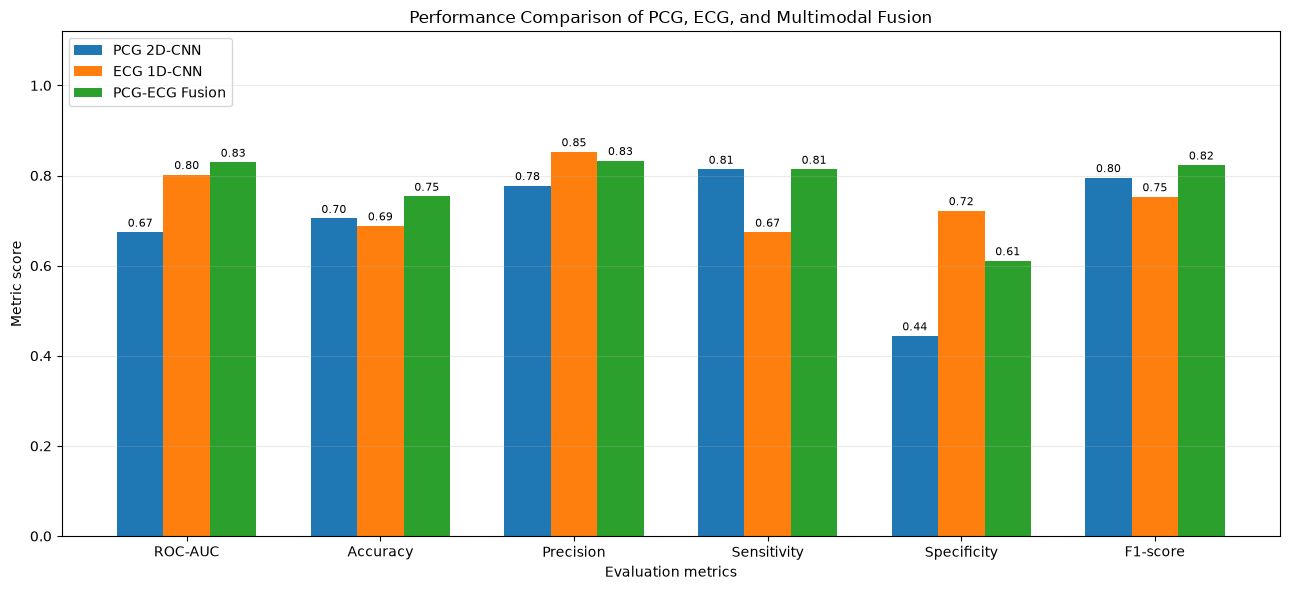

In [70]:
# Cell 22: Compare PCG, ECG, and Fusion Models

import numpy as np
import matplotlib.pyplot as plt

models = ["PCG 2D-CNN", "ECG 1D-CNN", "PCG-ECG Fusion"]

metrics = {
    "ROC-AUC":   [0.6744, 0.8023, 0.8295],
    "Accuracy":  [0.7049, 0.6885, 0.7541],
    "Precision": [0.7778, 0.8529, 0.8333],
    "Sensitivity": [0.8140, 0.6744, 0.8140],
    "Specificity": [0.4444, 0.7222, 0.6111],
    "F1-score":  [0.7955, 0.7532, 0.8235]
}

metric_names = list(metrics.keys())
x = np.arange(len(metric_names))
width = 0.24

fig, ax = plt.subplots(figsize=(13, 6))

for i, model in enumerate(models):
    values = [metrics[m][i] for m in metric_names]
    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=model
    )

    ax.bar_label(
        bars,
        labels=[f"{v:.2f}" for v in values],
        padding=2,
        fontsize=8
    )

ax.set_title("Performance Comparison of PCG, ECG, and Multimodal Fusion")
ax.set_ylabel("Metric score")
ax.set_xlabel("Evaluation metrics")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1.12)
ax.legend(loc="upper left")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [71]:
# Cell 23: Save model comparison results

import os
import pandas as pd
import matplotlib.pyplot as plt

output_dir = "../processed/model_evaluation"
os.makedirs(output_dir, exist_ok=True)

# Prepare comparison table using the verified test metrics
comparison_df = pd.DataFrame({
    "Metric": [
        "ROC-AUC", "Accuracy", "Precision",
        "Sensitivity", "Specificity", "F1-score"
    ],
    "PCG 2D-CNN": [
        0.6744, 0.7049, 0.7778,
        0.8140, 0.4444, 0.7955
    ],
    "ECG 1D-CNN": [
        0.8023, 0.6885, 0.8529,
        0.6744, 0.7222, 0.7532
    ],
    "PCG-ECG Fusion": [
        0.8295, 0.7541, 0.8333,
        0.8140, 0.6111, 0.8235
    ]
})

csv_path = os.path.join(output_dir, "model_comparison.csv")
comparison_df.to_csv(csv_path, index=False)

print("Saved comparison table:", csv_path)
display(comparison_df)

# Save the currently displayed comparison chart
chart_path = os.path.join(output_dir, "model_comparison.png")
plt.gcf().savefig(chart_path, dpi=300, bbox_inches="tight")

print("Saved comparison chart:", chart_path)

Saved comparison table: ../processed/model_evaluation\model_comparison.csv


,Metric,PCG 2D-CNN,ECG 1D-CNN,PCG-ECG Fusion
0,ROC-AUC,0.6744,0.8023,0.8295
1,Accuracy,0.7049,0.6885,0.7541
2,Precision,0.7778,0.8529,0.8333
3,Sensitivity,0.8140,0.6744,0.8140
4,Specificity,0.4444,0.7222,0.6111
5,F1-score,0.7955,0.7532,0.8235


Saved comparison chart: ../processed/model_evaluation\model_comparison.png


<Figure size 640x480 with 0 Axes>

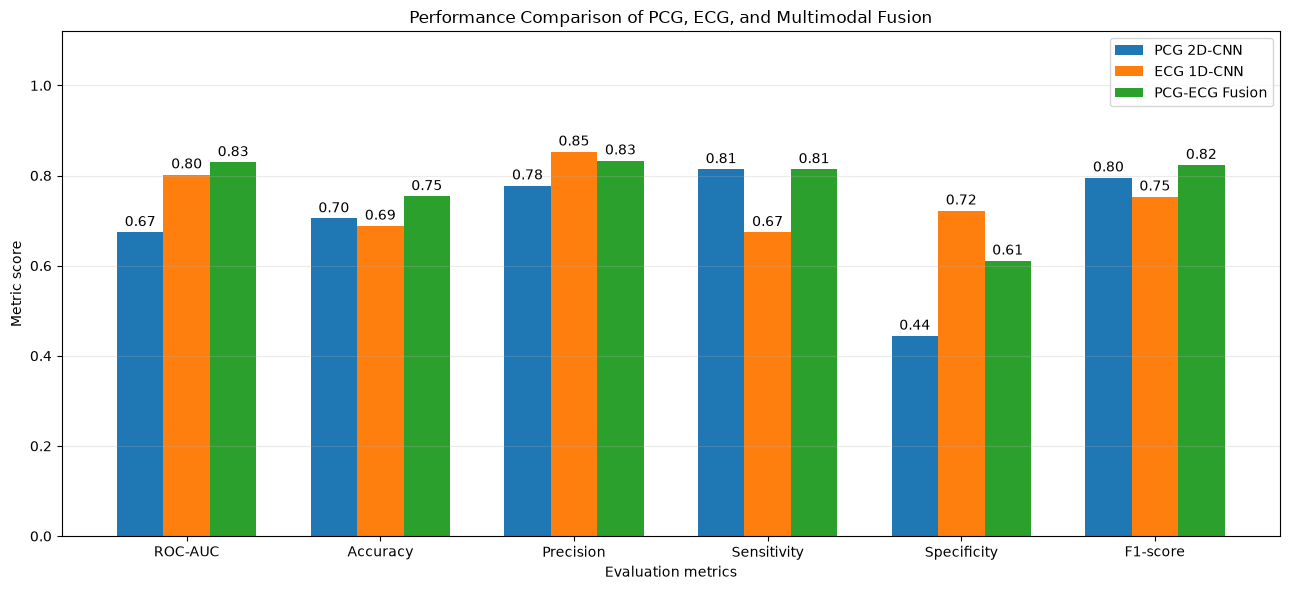

Final chart saved: ../processed/model_evaluation\model_comparison.png
Chart file size: 152851 bytes


In [72]:
# Cell 24: Recreate and save the final comparison chart

import os
import numpy as np
import matplotlib.pyplot as plt

output_dir = "../processed/model_evaluation"
os.makedirs(output_dir, exist_ok=True)

models = ["PCG 2D-CNN", "ECG 1D-CNN", "PCG-ECG Fusion"]

metrics = {
    "ROC-AUC": [0.6744, 0.8023, 0.8295],
    "Accuracy": [0.7049, 0.6885, 0.7541],
    "Precision": [0.7778, 0.8529, 0.8333],
    "Sensitivity": [0.8140, 0.6744, 0.8140],
    "Specificity": [0.4444, 0.7222, 0.6111],
    "F1-score": [0.7955, 0.7532, 0.8235]
}

metric_names = list(metrics.keys())
x = np.arange(len(metric_names))
width = 0.24

fig, ax = plt.subplots(figsize=(13, 6))

for i, model in enumerate(models):
    values = [metrics[m][i] for m in metric_names]
    bars = ax.bar(x + (i - 1) * width, values, width, label=model)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in values], padding=2)

ax.set_title("Performance Comparison of PCG, ECG, and Multimodal Fusion")
ax.set_ylabel("Metric score")
ax.set_xlabel("Evaluation metrics")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1.12)
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

chart_path = os.path.join(output_dir, "model_comparison.png")
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Final chart saved:", chart_path)
print("Chart file size:", os.path.getsize(chart_path), "bytes")

In [73]:
# Cell 25: Verify saved evaluation files

import os

output_dir = "../processed/model_evaluation"

expected_files = [
    "model_comparison.csv",
    "model_comparison.png"
]

for filename in expected_files:
    path = os.path.join(output_dir, filename)

    if os.path.exists(path):
        print(f"✅ {filename} — {os.path.getsize(path):,} bytes")
    else:
        print(f"❌ {filename} — NOT FOUND")

✅ model_comparison.csv — 235 bytes
✅ model_comparison.png — 152,851 bytes


In [74]:
# Cell 26: Check available Grad-CAM figures and variables

import os
import matplotlib.pyplot as plt

output_dir = "../processed/model_evaluation/gradcam"
os.makedirs(output_dir, exist_ok=True)

print("Grad-CAM variables available:")

gradcam_vars = [
    "ecg_heatmap_abnormal",
    "ecg_heatmap_fp",
    "sample_ecg_abnormal",
    "sample_ecg_fp",
    "ecg_grad_model",
    "ecg_normalized_abnormal",
    "ecg_normalized_fp"
]

for name in gradcam_vars:
    if name in globals():
        value = globals()[name]
        shape = getattr(value, "shape", None)
        print(f"✅ {name}: {shape if shape is not None else type(value).__name__}")
    else:
        print(f"❌ {name}: not found")

print("\nGrad-CAM output folder:", os.path.abspath(output_dir))

Grad-CAM variables available:
✅ ecg_heatmap_abnormal: (1000,)
✅ ecg_heatmap_fp: (1000,)
✅ sample_ecg_abnormal: (1, 4000, 1)
✅ sample_ecg_fp: (1, 4000, 1)
✅ ecg_grad_model: Functional
✅ ecg_normalized_abnormal: (4000,)
✅ ecg_normalized_fp: (4000,)

Grad-CAM output folder: C:\Users\HP\Desktop\RHD_Project\processed\model_evaluation\gradcam


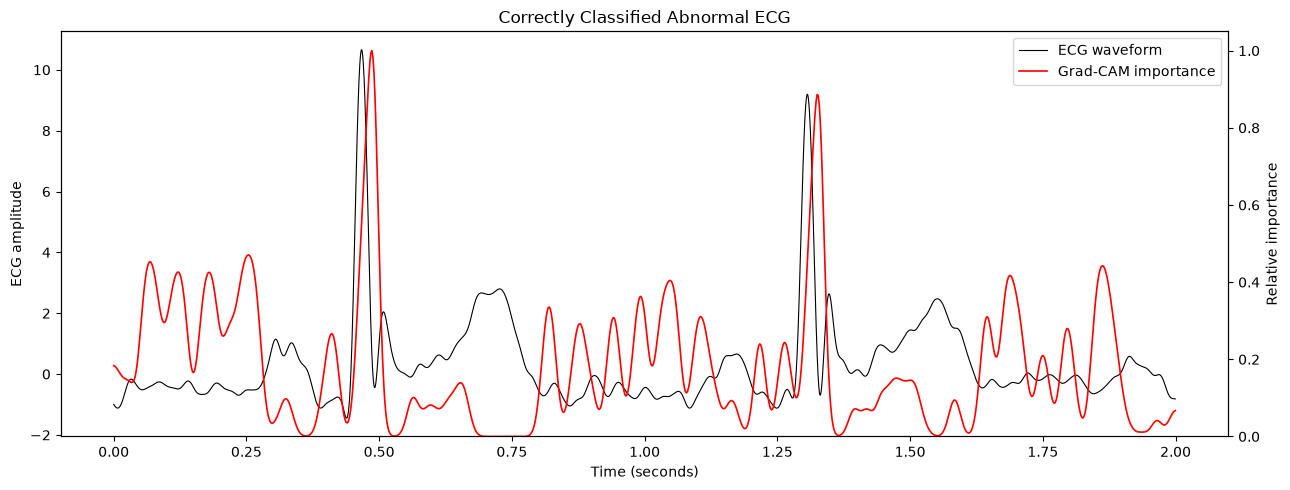

Saved: ../processed/model_evaluation/gradcam\correctly_classified_abnormal_ecg.png
File size: 315,241 bytes


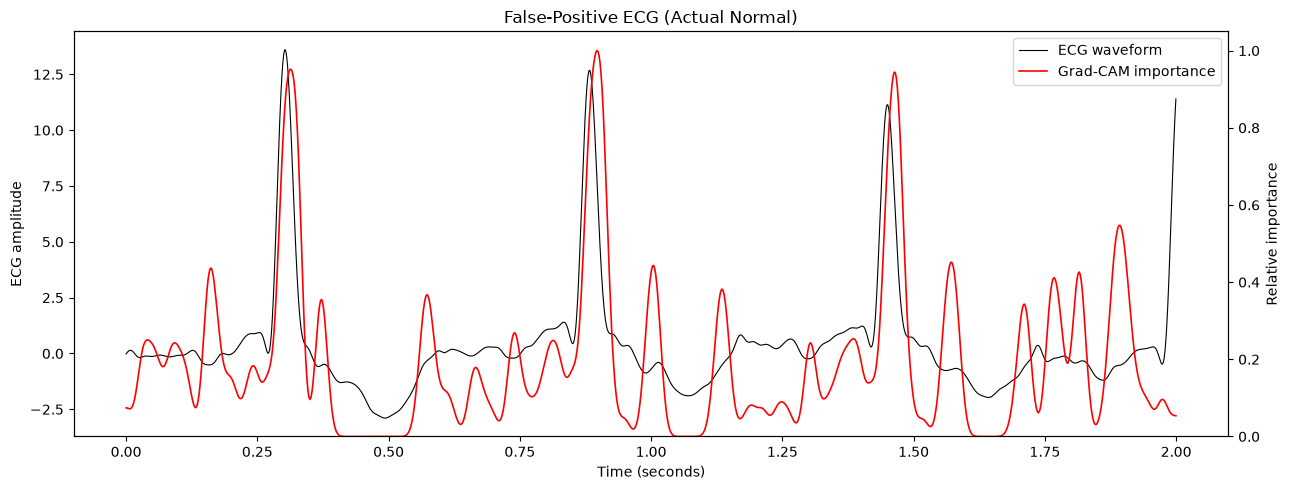

Saved: ../processed/model_evaluation/gradcam\false_positive_normal_ecg.png
File size: 318,463 bytes


In [75]:
# Cell 27: Save ECG Grad-CAM figures

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

output_dir = "../processed/model_evaluation/gradcam"
os.makedirs(output_dir, exist_ok=True)

examples = [
    {
        "name": "correctly_classified_abnormal_ecg",
        "title": "Correctly Classified Abnormal ECG",
        "sample": sample_ecg_abnormal,
        "heatmap": ecg_heatmap_abnormal,
    },
    {
        "name": "false_positive_normal_ecg",
        "title": "False-Positive ECG (Actual Normal)",
        "sample": sample_ecg_fp,
        "heatmap": ecg_heatmap_fp,
    },
]

for example in examples:
    ecg = np.asarray(example["sample"])[0, :, 0]
    heatmap = np.asarray(example["heatmap"]).reshape(-1)

    time_ecg = np.arange(len(ecg)) / 2000
    time_heatmap = np.linspace(
        time_ecg[0], time_ecg[-1], len(heatmap)
    )

    smooth_heatmap = gaussian_filter1d(heatmap, sigma=5)
    smooth_heatmap = np.maximum(smooth_heatmap, 0)
    smooth_heatmap /= smooth_heatmap.max() + 1e-8

    fig, ax1 = plt.subplots(figsize=(13, 5))

    ax1.plot(
        time_ecg, ecg,
        color="black", linewidth=0.8,
        label="ECG waveform"
    )
    ax1.set_xlabel("Time (seconds)")
    ax1.set_ylabel("ECG amplitude")
    ax1.set_title(example["title"])

    ax2 = ax1.twinx()
    ax2.plot(
        time_heatmap, smooth_heatmap,
        color="red", linewidth=1.2,
        label="Grad-CAM importance"
    )
    ax2.set_ylabel("Relative importance")
    ax2.set_ylim(0, 1.05)

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

    fig.tight_layout()

    save_path = os.path.join(
        output_dir, example["name"] + ".png"
    )
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {save_path}")
    print(f"File size: {os.path.getsize(save_path):,} bytes")

In [76]:
# Cell 28: Check PCG Grad-CAM variables

pcg_gradcam_vars = [
    "pcg_grad_model",
    "pcg_heatmap",
    "pcg_heatmap_fp",
    "sample_pcg",
    "sample_pcg_fp",
    "pcg_spectrogram",
    "pcg_test_sample",
    "clean_pcg_model"
]

for name in pcg_gradcam_vars:
    if name in globals():
        value = globals()[name]
        shape = getattr(value, "shape", None)
        print(f"✅ {name}: {shape if shape is not None else type(value).__name__}")
    else:
        print(f"— {name}: not found")

— pcg_grad_model: not found
— pcg_heatmap: not found
— pcg_heatmap_fp: not found
— sample_pcg: not found
— sample_pcg_fp: not found
— pcg_spectrogram: not found
— pcg_test_sample: not found
✅ clean_pcg_model: Sequential


In [77]:
# Cell 29: Inspect PCG CNN layers for Grad-CAM

for i, layer in enumerate(clean_pcg_model.layers):
    try:
        output_shape = layer.output.shape
    except Exception:
        output_shape = "not available"

    print(
        f"Layer {i}: {layer.name} | "
        f"{layer.__class__.__name__} | "
        f"Output: {output_shape}"
    )

Layer 0: conv2d | Conv2D | Output: (None, 40, 19, 32)
Layer 1: batch_normalization | BatchNormalization | Output: (None, 40, 19, 32)
Layer 2: max_pooling2d | MaxPooling2D | Output: (None, 20, 9, 32)
Layer 3: conv2d_1 | Conv2D | Output: (None, 20, 9, 64)
Layer 4: batch_normalization_1 | BatchNormalization | Output: (None, 20, 9, 64)
Layer 5: max_pooling2d_1 | MaxPooling2D | Output: (None, 10, 4, 64)
Layer 6: conv2d_2 | Conv2D | Output: (None, 10, 4, 128)
Layer 7: batch_normalization_2 | BatchNormalization | Output: (None, 10, 4, 128)
Layer 8: global_average_pooling2d | GlobalAveragePooling2D | Output: (None, 128)
Layer 9: dropout_3 | Dropout | Output: (None, 128)
Layer 10: dense_2 | Dense | Output: (None, 64)
Layer 11: dropout_4 | Dropout | Output: (None, 64)
Layer 12: rhd_probability | Dense | Output: (None, 1)


In [79]:
# Cell 30: Build PCG Grad-CAM model safely

import tensorflow as tf
import numpy as np

# Get the final convolutional layer
last_conv_layer = clean_pcg_model.get_layer("conv2d_2")

# Explicitly call the model to build its computation graph
sample_batch = np.asarray(
    X_pcg_test_cnn[:1], dtype=np.float32
)

_ = clean_pcg_model(sample_batch, training=False)

# Build a functional model from the existing trained layers
pcg_input = tf.keras.Input(shape=(40, 19, 1))

x = pcg_input
conv_output = None

for layer in clean_pcg_model.layers:
    x = layer(x, training=False) if isinstance(
        layer, tf.keras.layers.BatchNormalization
    ) or isinstance(layer, tf.keras.layers.Dropout) else layer(x)

    if layer.name == "conv2d_2":
        conv_output = x

pcg_grad_model = tf.keras.Model(
    inputs=pcg_input,
    outputs=[conv_output, x],
    name="pcg_gradcam_model"
)

# Verify prediction consistency
original_prob = clean_pcg_model(
    sample_batch, training=False
).numpy().reshape(-1)[0]

_, gradcam_prob = pcg_grad_model(
    sample_batch, training=False
)

gradcam_prob = gradcam_prob.numpy().reshape(-1)[0]

print("PCG Grad-CAM model built successfully.")
print(f"Original probability: {original_prob:.6f}")
print(f"Grad-CAM probability: {gradcam_prob:.6f}")
print(f"Difference: {abs(original_prob - gradcam_prob):.10f}")

PCG Grad-CAM model built successfully.
Original probability: 0.886517
Grad-CAM probability: 0.886517
Difference: 0.0000000000


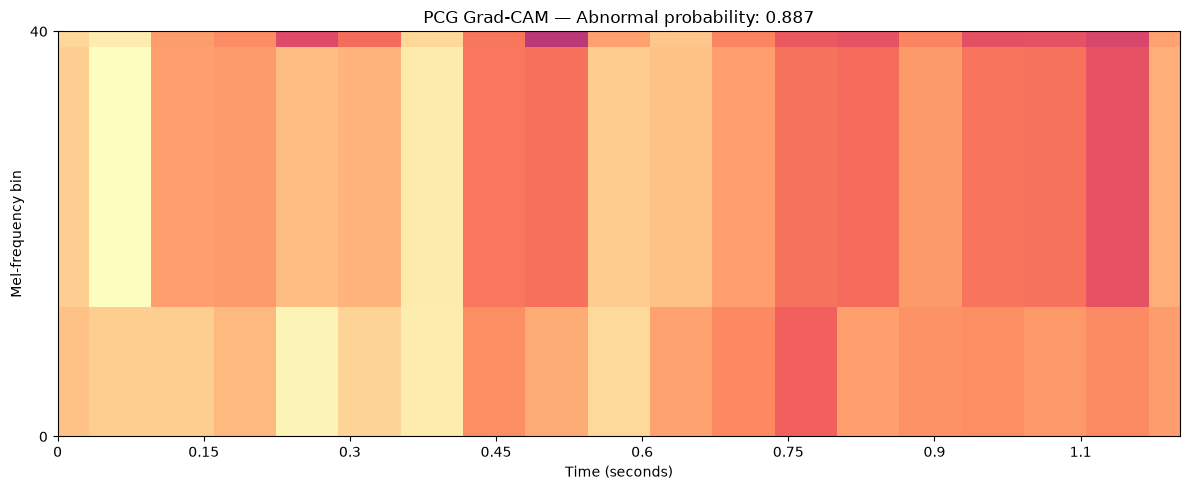

PCG Grad-CAM saved: ../processed/model_evaluation/gradcam\pcg_gradcam_example.png
Abnormal probability: 0.8865171074867249
File size: 70851 bytes


In [80]:
# Cell 31: Generate PCG Grad-CAM heatmap

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import librosa.display

# Select one test PCG recording segment
sample_pcg = np.asarray(X_pcg_test_cnn[:1], dtype=np.float32)

# Calculate Grad-CAM
with tf.GradientTape() as tape:
    conv_features, prediction = pcg_grad_model(
        sample_pcg, training=False
    )
    abnormal_score = prediction[:, 0]

gradients = tape.gradient(
    abnormal_score, conv_features
)

# Average gradients across spatial dimensions
weights = tf.reduce_mean(
    gradients, axis=(1, 2), keepdims=True
)

# Weighted sum of convolutional feature maps
heatmap = tf.reduce_sum(
    weights * conv_features, axis=-1
)
heatmap = tf.nn.relu(heatmap)[0].numpy()

# Normalize heatmap
heatmap = heatmap / (heatmap.max() + 1e-8)
pcg_heatmap = heatmap

# Original log-Mel spectrogram
pcg_spectrogram = sample_pcg[0, :, :, 0]

# Plot the spectrogram with Grad-CAM overlay
fig, ax = plt.subplots(figsize=(12, 5))

librosa.display.specshow(
    pcg_spectrogram,
    sr=2000,
    hop_length=128,
    x_axis="time",
    y_axis="mel",
    ax=ax
)

ax.imshow(
    pcg_heatmap,
    aspect="auto",
    origin="lower",
    extent=[
        0,
        (pcg_spectrogram.shape[1] - 1) * 128 / 2000,
        0,
        40
    ],
    cmap="jet",
    alpha=0.45,
    interpolation="bilinear"
)

ax.set_title(
    f"PCG Grad-CAM — Abnormal probability: "
    f"{float(abnormal_score.numpy()[0]):.3f}"
)
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Mel-frequency bin")

plt.tight_layout()

output_dir = "../processed/model_evaluation/gradcam"
os.makedirs(output_dir, exist_ok=True)

save_path = os.path.join(
    output_dir, "pcg_gradcam_example.png"
)

fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("PCG Grad-CAM saved:", save_path)
print("Abnormal probability:", float(abnormal_score.numpy()[0]))
print("File size:", os.path.getsize(save_path), "bytes")

In [81]:
# Cell 32: Verify final evaluation outputs

import os

output_dir = "../processed/model_evaluation"

expected_files = [
    "model_comparison.csv",
    "model_comparison.png",
    "gradcam/pcg_gradcam_example.png",
    "gradcam/correctly_classified_abnormal_ecg.png",
    "gradcam/false_positive_normal_ecg.png",
]

print("FINAL PROJECT OUTPUT CHECK")
print("-" * 40)

all_found = True

for filename in expected_files:
    path = os.path.join(output_dir, filename)

    if os.path.isfile(path) and os.path.getsize(path) > 0:
        print(f"✅ {filename}")
    else:
        print(f"❌ Missing or empty: {filename}")
        all_found = False

print("-" * 40)
print(
    "All expected files are present!"
    if all_found
    else "Please check the missing files above."
)

FINAL PROJECT OUTPUT CHECK
----------------------------------------
✅ model_comparison.csv
✅ model_comparison.png
✅ gradcam/pcg_gradcam_example.png
✅ gradcam/correctly_classified_abnormal_ecg.png
✅ gradcam/false_positive_normal_ecg.png
----------------------------------------
All expected files are present!
